# EDA awal sebelum penanganan UTS
Jalankan **Run all** dan izinkan mount Drive. Dataset asli dibaca dari ZIP yang tersedia pada folder proyek. Label awal dipertahankan untuk memperlihatkan temuan EDA sebelum koreksi UTS.
Hasil tersimpan di `MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS`.


# Cell A1 — Lokasi data dan fungsi dasar

In [2]:
import importlib.util, subprocess, sys
packages={'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','PIL':'pillow','cv2':'opencv-python-headless','yaml':'pyyaml','sklearn':'scikit-learn'}
for module,package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])

# Lokasi Drive sesuai folder yang diberikan pengguna.
from pathlib import Path, PurePosixPath
import os, json, hashlib, unicodedata, zipfile, shutil

PROJECT_NAME = '1226800011_Aprilia_UjianEDA_Revisi'
YOLO_FOLDER = 'enumerasi gigi susu6-252-.v1i.yolov11'
YOLO_ZIP = 'enumerasi_gigi_susu_252_label_asli.zip'

def normal_name(value):
    return ' '.join(unicodedata.normalize('NFKC', value).split()).casefold()

def get_project_root():
    try:
        from google.colab import drive
    except ImportError:
        # Hanya untuk verifikasi lokal. Di Colab, lokasi default tetap /content/drive.
        pass
    else:
        drive.mount('/content/drive')
    mydrive = Path(os.environ.get('FDI_MYDRIVE', '/content/drive/MyDrive'))
    direct = mydrive / PROJECT_NAME
    if direct.is_dir():
        return direct
    if not mydrive.is_dir():
        raise FileNotFoundError('Drive belum tersedia. Jalankan notebook ini di Google Colab dan izinkan akses Drive.')
    matches = [p for p in mydrive.iterdir()
               if p.is_dir() and normal_name(p.name) == normal_name(PROJECT_NAME)]
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Folder {PROJECT_NAME!r} belum ditemukan secara unik pada {mydrive}. '
            'Pastikan akun saat mount Drive adalah akun pemilik folder tersebut. '
            f'Kandidat: {matches}'
        )
    return matches[0]

def yolo_is_complete(root):
    images = root / 'train' / 'images'
    labels = root / 'train' / 'labels'
    if not ((root / 'data.yaml').is_file() and images.is_dir() and labels.is_dir()):
        return False
    paths = [p for p in images.iterdir()
             if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}]
    return len(paths) == 252 and all((labels / (p.stem + '.txt')).is_file() for p in paths)

def get_raw_yolo(project_root):
    unpacked = project_root / YOLO_FOLDER
    if yolo_is_complete(unpacked):
        print('Ekspor YOLO asli:', unpacked)
        return unpacked
    archive = project_root / YOLO_ZIP
    if not archive.is_file():
        raise FileNotFoundError(
            f'Ekspor YOLO dengan label FDI belum tersedia. Letakkan {YOLO_ZIP} '
            f'atau folder {YOLO_FOLDER} pada {project_root}. '
            'Empat folder sumber saja belum memuat label FDI yang diperlukan.'
        )
    digest = hashlib.sha256()
    with archive.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    scratch = Path(os.environ.get('FDI_SCRATCH', '/content'))
    extracted = scratch / ('fdi_raw_' + digest.hexdigest()[:12])
    root = extracted / YOLO_FOLDER
    if not yolo_is_complete(root):
        extracted.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            if z.testzip() is not None:
                raise RuntimeError('ZIP belum lengkap atau rusak. Tunggu unggahan selesai lalu jalankan ulang.')
            for info in z.infolist():
                rel = PurePosixPath(info.filename)
                if rel.is_absolute() or '..' in rel.parts or chr(92) in info.filename:
                    raise ValueError('ZIP memiliki lokasi file yang tidak aman.')
                if ((info.external_attr >> 16) & 0o170000) == 0o120000:
                    raise ValueError('ZIP dengan symbolic link tidak digunakan.')
                target = (extracted / Path(*rel.parts)).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError('Lokasi ekstraksi keluar dari folder tujuan.')
            z.extractall(extracted)
    if not yolo_is_complete(root):
        raise RuntimeError('Ekspor YOLO harus memuat data.yaml, 252 citra dan pasangan file label aslinya.')
    print('ZIP YOLO diekstrak otomatis ke penyimpanan lokal runtime:', root)
    return root

PROJECT_ROOT = get_project_root()
print('Folder proyek Drive:', PROJECT_ROOT)


RAW_YOLO = get_raw_yolo(PROJECT_ROOT)
EDA_HOME = PROJECT_ROOT / 'hasil_EDA_awal_sebelum_UTS'
EDA_HOME.mkdir(exist_ok=True)


from pathlib import Path
from collections import Counter
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2
from IPython.display import display


# ============================================================
# 1. TEMUKAN DAN VALIDASI FOLDER INPUT
# ============================================================

MYDRIVE = Path(os.environ.get("FDI_MYDRIVE", "/content/drive/MyDrive"))

def normalisasi_folder(nama):
    # Mengatasi perbedaan kapital, spasi berlebih, dan karakter Unicode.
    nama = unicodedata.normalize("NFKC", nama)
    return " ".join(nama.split()).casefold()


def cari_subfolder(induk, nama):
    if not induk.is_dir():
        raise FileNotFoundError(f"Folder induk tidak ditemukan: {induk}")

    cocok = [
        p for p in induk.iterdir()
        if p.is_dir()
        and normalisasi_folder(p.name) == normalisasi_folder(nama)
    ]

    if len(cocok) == 1:
        return cocok[0]

    print(f"\nIsi folder {induk}:")
    for p in sorted(induk.iterdir()):
        print(f"  {'FOLDER' if p.is_dir() else 'FILE'}: {p.name!r}")

    if len(cocok) > 1:
        raise RuntimeError(
            f"Ada beberapa folder yang cocok dengan {nama!r}. "
            "Lokasinya perlu dipastikan."
        )

    raise FileNotFoundError(
        f"Folder {nama!r} tidak ditemukan di {induk}. "
        "Periksa daftar di atas dan akun Google Drive yang terhubung."
    )


BASE = PROJECT_ROOT

NAMA_FOLDER = {
    "Paramita 2016–2018": "DENTAL DATASET PARAMITA 2016-2018",
    "Paramita 2026": "Dataset PARAMITA 2026",
    "Kaggle": "Childrens dental caries segmentation dataset_KAGEL",
}

# Semua folder input harus valid sebelum membuat folder hasil.
FOLDERS = {
    sumber: cari_subfolder(BASE, nama)
    for sumber, nama in NAMA_FOLDER.items()
}

KANDIDAT = cari_subfolder(
    BASE, "Data terpilih dari Dental Paramita 11-12"
)
FINAL = RAW_YOLO / "train" / "images"

HASIL = EDA_HOME / "hasil_EDA_sebelum_label"
HASIL.mkdir(exist_ok=True)


# ============================================================
# 2. KONFIGURASI
# ============================================================

SEED = 42
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

EXCLUDED_DIRS = {
    "mask", "masks", "label", "labels",
    "annotation", "annotations",
    "ground_truth", "groundtruth"
}


# ============================================================
# 3. FUNGSI PEMBACAAN DATA
# ============================================================

def daftar_gambar(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder tidak ditemukan: {folder}")

    result = []

    for p in sorted(folder.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in EXT:
            continue

        relative = p.relative_to(folder)

        if any(
            bagian.lower() in EXCLUDED_DIRS
            for bagian in relative.parts[:-1]
        ):
            continue

        if re.search(
            r"(^|[_\-.])(mask|label)([_\-.]|$)",
            p.stem,
            re.I
        ):
            continue

        result.append(p)

    return result


def sumber_final(nama):
    nama = nama.lower()

    if nama.startswith("cate"):
        return "Kaggle"

    if nama.startswith("sulung"):
        return "Paramita 2026"

    return "Paramita 2016–2018"


def kunci_nama(nama):
    s = re.split(r"\.rf\.", Path(nama).stem.lower())[0]
    s = re.sub(r"_(jpg|jpeg|png|bmp|tif|tiff)$", "", s)
    s = re.sub(r"[^a-z0-9]", "", s)

    # Kesetaraan kedua nama HANA telah dikonfirmasi.
    if s == "345hanaan4th1":
        s = "345hanaan4th"

    return s


def umur_file(nama):
    # Cate dan sulung tidak mempunyai keterangan umur.
    if sumber_final(nama) != "Paramita 2016–2018":
        return np.nan

    values = set(re.findall(
        r"(\d+)[ _-]*TH(?:N)?(?=[_. -]|$)",
        nama,
        re.I
    ))

    return float(next(iter(values))) if len(values) == 1 else np.nan


def simpan_grafik(nama):
    plt.tight_layout()
    plt.savefig(
        HASIL / f"{nama}.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# ============================================================
# 4. KONFIRMASI LOKASI
# ============================================================

print("Seluruh folder input berhasil ditemukan.\n")
print("BASE:", BASE)

for sumber, folder in FOLDERS.items():
    print(f"{sumber}: {folder}")

print("Kandidat:", KANDIDAT)
print("Final:", FINAL)
print("Lokasi hasil:", HASIL)

Mounted at /content/drive
Folder proyek Drive: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi
ZIP YOLO diekstrak otomatis ke penyimpanan lokal runtime: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11
Seluruh folder input berhasil ditemukan.

BASE: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi
Paramita 2016–2018: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/DENTAL DATASET PARAMITA 2016-2018
Paramita 2026: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/Dataset PARAMITA 2026
Kaggle: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/Childrens dental caries segmentation dataset_KAGEL
Kandidat: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/Data terpilih dari Dental Paramita 11-12
Final: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11/train/images
Lokasi hasil: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/hasil_EDA_sebelum_label


# Cell A2 — Tabel tiga sumber dan alur seleksi

Folder final yang digunakan:
/content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11/train/images


,Sumber,Jumlah final menurut catatan,Jumlah final ditemukan,Sesuai
0,Paramita 2016–2018,121,121,True
1,Paramita 2026,48,48,True
2,Kaggle,83,83,True


TOTAL FINAL: 252 gambar = 83 cate + 48 sulung + 121 lainnya

Kandidat Paramita: 171
Kandidat cocok dengan final: 121
Kandidat belum cocok dengan final: 50


,Sumber,Data awal — catatan,File gambar ditemukan,Kandidat,Terpilih final,Selisih kandidat–final
0,Paramita 2016–2018,2039,2039,171,121,50
1,Paramita 2026,69,67,67,48,19
2,Kaggle,100,100,100,83,17


Catatan Paramita 2026: ditemukan 67 file gambar, sedangkan catatan penelitian 69. Perbedaan jumlah perlu diperiksa.


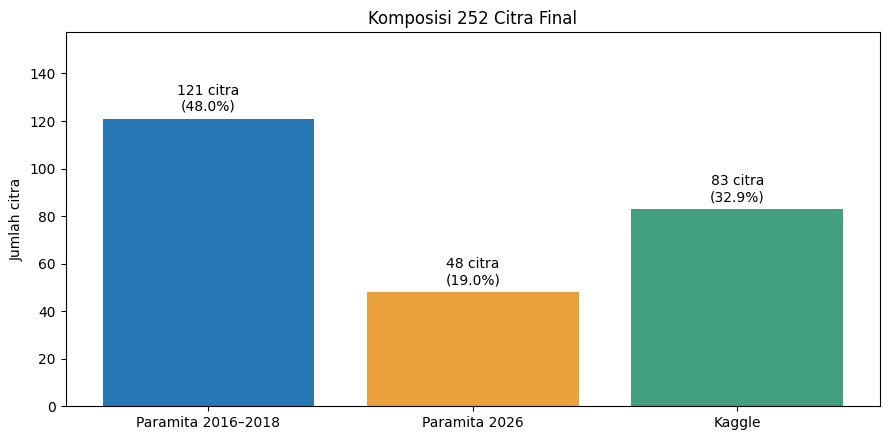

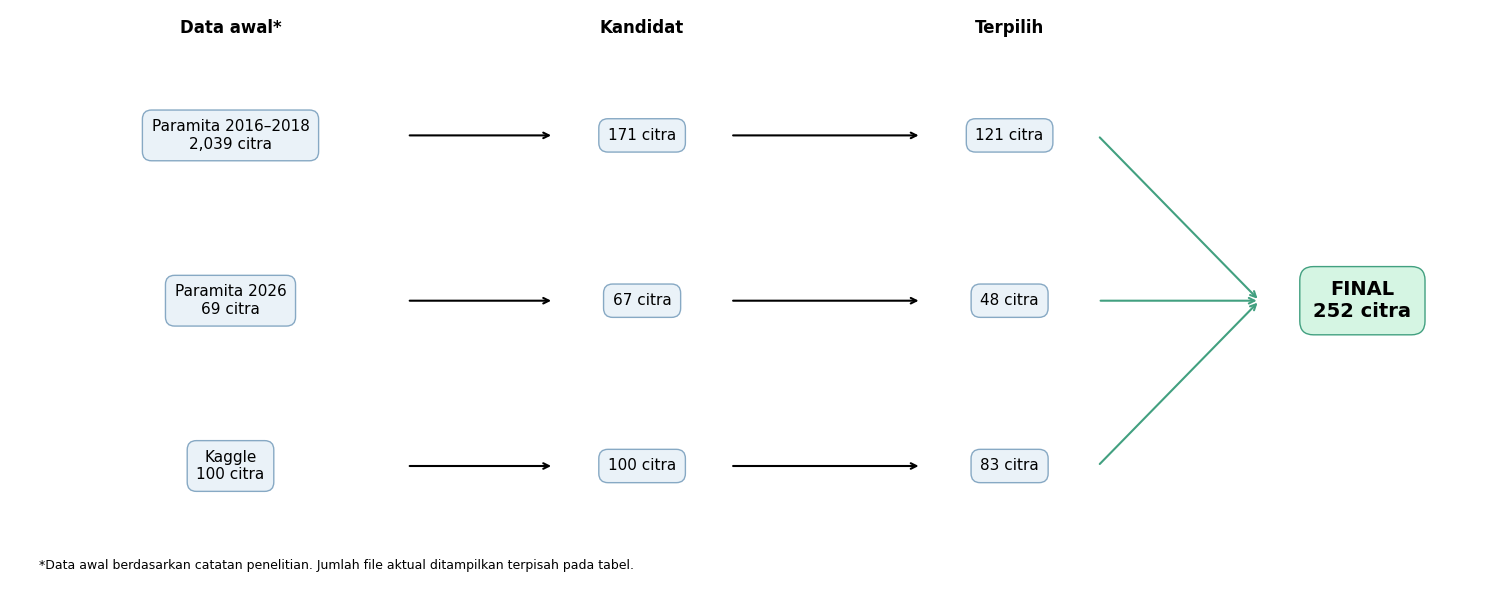


Selesai. Hasil tersimpan di:
/content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/hasil_EDA_sebelum_label


In [3]:
# ============================================================
# CELL 2 — KOMPOSISI DAN ALUR SELEKSI
# Jalankan setelah Cell 1 berhasil.
# ============================================================

# Gunakan BASE, FOLDERS, KANDIDAT, dan HASIL dari Cell 1.
# Jangan menuliskan ulang path BASE secara manual.

DATASET_YOLO = RAW_YOLO
TRAIN_FOLDER = cari_subfolder(DATASET_YOLO, "train")
FINAL = cari_subfolder(TRAIN_FOLDER, "images")

print("Folder final yang digunakan:")
print(FINAL)


# ------------------------------------------------------------
# 1. BACA FILE
# ------------------------------------------------------------

file_sumber = {
    sumber: daftar_gambar(folder)
    for sumber, folder in FOLDERS.items()
}

file_kandidat = daftar_gambar(KANDIDAT)

# Folder images YOLO berisi citra final.
file_final = sorted(
    p for p in FINAL.rglob("*")
    if p.is_file()
    and p.suffix.lower() in EXT.union({".webp"})
)

komposisi = Counter(
    sumber_final(p.name) for p in file_final
)

urutan = [
    "Paramita 2016–2018",
    "Paramita 2026",
    "Kaggle"
]

catatan_awal = {
    "Paramita 2016–2018": 2039,
    "Paramita 2026": 69,
    "Kaggle": 100
}

target_final = {
    "Paramita 2016–2018": 121,
    "Paramita 2026": 48,
    "Kaggle": 83
}


# ------------------------------------------------------------
# 2. VERIFIKASI KOMPOSISI
# ------------------------------------------------------------

pemeriksaan = pd.DataFrame([
    {
        "Sumber": sumber,
        "Jumlah final menurut catatan": target_final[sumber],
        "Jumlah final ditemukan": komposisi[sumber],
        "Sesuai": komposisi[sumber] == target_final[sumber]
    }
    for sumber in urutan
])

display(pemeriksaan)

print(
    f"TOTAL FINAL: {len(file_final)} gambar = "
    f"{komposisi['Kaggle']} cate + "
    f"{komposisi['Paramita 2026']} sulung + "
    f"{komposisi['Paramita 2016–2018']} lainnya"
)

if not pemeriksaan["Sesuai"].all():
    print("\nContoh nama file yang ditemukan:")
    for p in file_final[:15]:
        print(p.name)

    raise ValueError(
        "Folder berhasil ditemukan, tetapi komposisinya "
        "belum sesuai 121 + 48 + 83. Periksa isi folder."
    )


# ------------------------------------------------------------
# 3. PENCOCOKAN KANDIDAT PARAMITA DENGAN FINAL
# ------------------------------------------------------------

kunci_final_paramita = {
    kunci_nama(p.name)
    for p in file_final
    if sumber_final(p.name) == "Paramita 2016–2018"
}

tidak_terpilih = [
    p for p in file_kandidat
    if kunci_nama(p.name) not in kunci_final_paramita
]

print("\nKandidat Paramita:", len(file_kandidat))
print(
    "Kandidat cocok dengan final:",
    len(file_kandidat) - len(tidak_terpilih)
)
print("Kandidat belum cocok dengan final:", len(tidak_terpilih))

pd.DataFrame({
    "filename": [p.name for p in tidak_terpilih],
    "alasan_terkonfirmasi": [""] * len(tidak_terpilih)
}).to_csv(
    HASIL / "02_daftar_kandidat_tidak_terpilih.csv",
    index=False
)


# ------------------------------------------------------------
# 4. TABEL ALUR SELEKSI
# ------------------------------------------------------------

jumlah_kandidat = {
    "Paramita 2016–2018": len(file_kandidat),
    "Paramita 2026": len(file_sumber["Paramita 2026"]),
    "Kaggle": len(file_sumber["Kaggle"])
}

tabel_seleksi = pd.DataFrame([
    {
        "Sumber": sumber,
        "Data awal — catatan": catatan_awal[sumber],
        "File gambar ditemukan": len(file_sumber[sumber]),
        "Kandidat": jumlah_kandidat[sumber],
        "Terpilih final": komposisi[sumber],
        "Selisih kandidat–final":
            jumlah_kandidat[sumber] - komposisi[sumber]
    }
    for sumber in urutan
])

display(tabel_seleksi)

tabel_seleksi.to_csv(
    HASIL / "01_alur_seleksi.csv",
    index=False
)

for sumber in urutan:
    aktual = len(file_sumber[sumber])
    catatan = catatan_awal[sumber]

    if aktual != catatan:
        print(
            f"Catatan {sumber}: ditemukan {aktual} file gambar, "
            f"sedangkan catatan penelitian {catatan}. "
            "Perbedaan jumlah perlu diperiksa."
        )


# ------------------------------------------------------------
# 5. GRAFIK KOMPOSISI FINAL
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4.5))

nilai = [komposisi[s] for s in urutan]

bars = ax.bar(
    urutan,
    nilai,
    color=["#2878B5", "#E9A23B", "#42A080"]
)

for bar, n in zip(bars, nilai):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        n + 2,
        f"{n} citra\n({n / len(file_final) * 100:.1f}%)",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, max(nilai) * 1.3)
ax.set_ylabel("Jumlah citra")
ax.set_title(f"Komposisi {len(file_final)} Citra Final")

simpan_grafik("01_komposisi_dataset")


# ------------------------------------------------------------
# 6. DIAGRAM ALUR SELEKSI
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

posisi_x = [0.15, 0.43, 0.68]
posisi_y = [0.78, 0.49, 0.20]

for x, teks in zip(
    posisi_x,
    ["Data awal*", "Kandidat", "Terpilih"]
):
    ax.text(
        x, 0.96, teks,
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

for y, sumber in zip(posisi_y, urutan):
    isi_kotak = [
        f"{sumber}\n{catatan_awal[sumber]:,} citra",
        f"{jumlah_kandidat[sumber]} citra",
        f"{komposisi[sumber]} citra"
    ]

    for x, teks in zip(posisi_x, isi_kotak):
        ax.text(
            x, y, teks,
            ha="center",
            va="center",
            fontsize=11,
            bbox=dict(
                boxstyle="round,pad=.6",
                facecolor="#EAF2F8",
                edgecolor="#87A9C4"
            )
        )

    for mulai, akhir in [(0.27, 0.37), (0.49, 0.62)]:
        ax.annotate(
            "",
            xy=(akhir, y),
            xytext=(mulai, y),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

    ax.annotate(
        "",
        xy=(0.85, 0.49),
        xytext=(0.74, y),
        arrowprops=dict(
            arrowstyle="->",
            color="#42A080",
            lw=1.5
        )
    )

ax.text(
    0.92, 0.49,
    f"FINAL\n{len(file_final)} citra",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=.7",
        facecolor="#D5F5E3",
        edgecolor="#42A080"
    )
)

ax.text(
    0.02, 0.02,
    "*Data awal berdasarkan catatan penelitian. "
    "Jumlah file aktual ditampilkan terpisah pada tabel.",
    fontsize=9
)

simpan_grafik("02_alur_seleksi")

print("\nSelesai. Hasil tersimpan di:")
print(HASIL)

# Cell A3 — Daftar 50 kandidat yang tidak masuk final dan lima contohnya

Jumlah kandidat Paramita: 171
Cocok dengan dataset final: 121
Belum ditemukan di dataset final: 50


,filename,umur,alasan_terkonfirmasi,catatan
0,"0046.ALIFA,AN.11TH.jpg",11.0,,
1,0053.ZAHRA.12 THN.jpg,12.0,,
2,"0109.DINI S,NN.12TH.jpg",12.0,,
3,"064.M AFFAN,AN.12TH.jpg",12.0,,
4,1017.celline.10 thn.jpg,10.0,,
5,1057.SEPTIA M.12 THN.jpg,12.0,,
6,"1095.M DYKKI.AN,11 TH.jpg",11.0,,
7,"1109.ZAHRA PUTRI,AN.11TH.jpg",11.0,,
8,"1117.ELENA JOYVE,AN.4TH^.jpg",NaN,,
9,"1228.IBRAHIM ANDRI,SDR.12TH.jpg",12.0,,


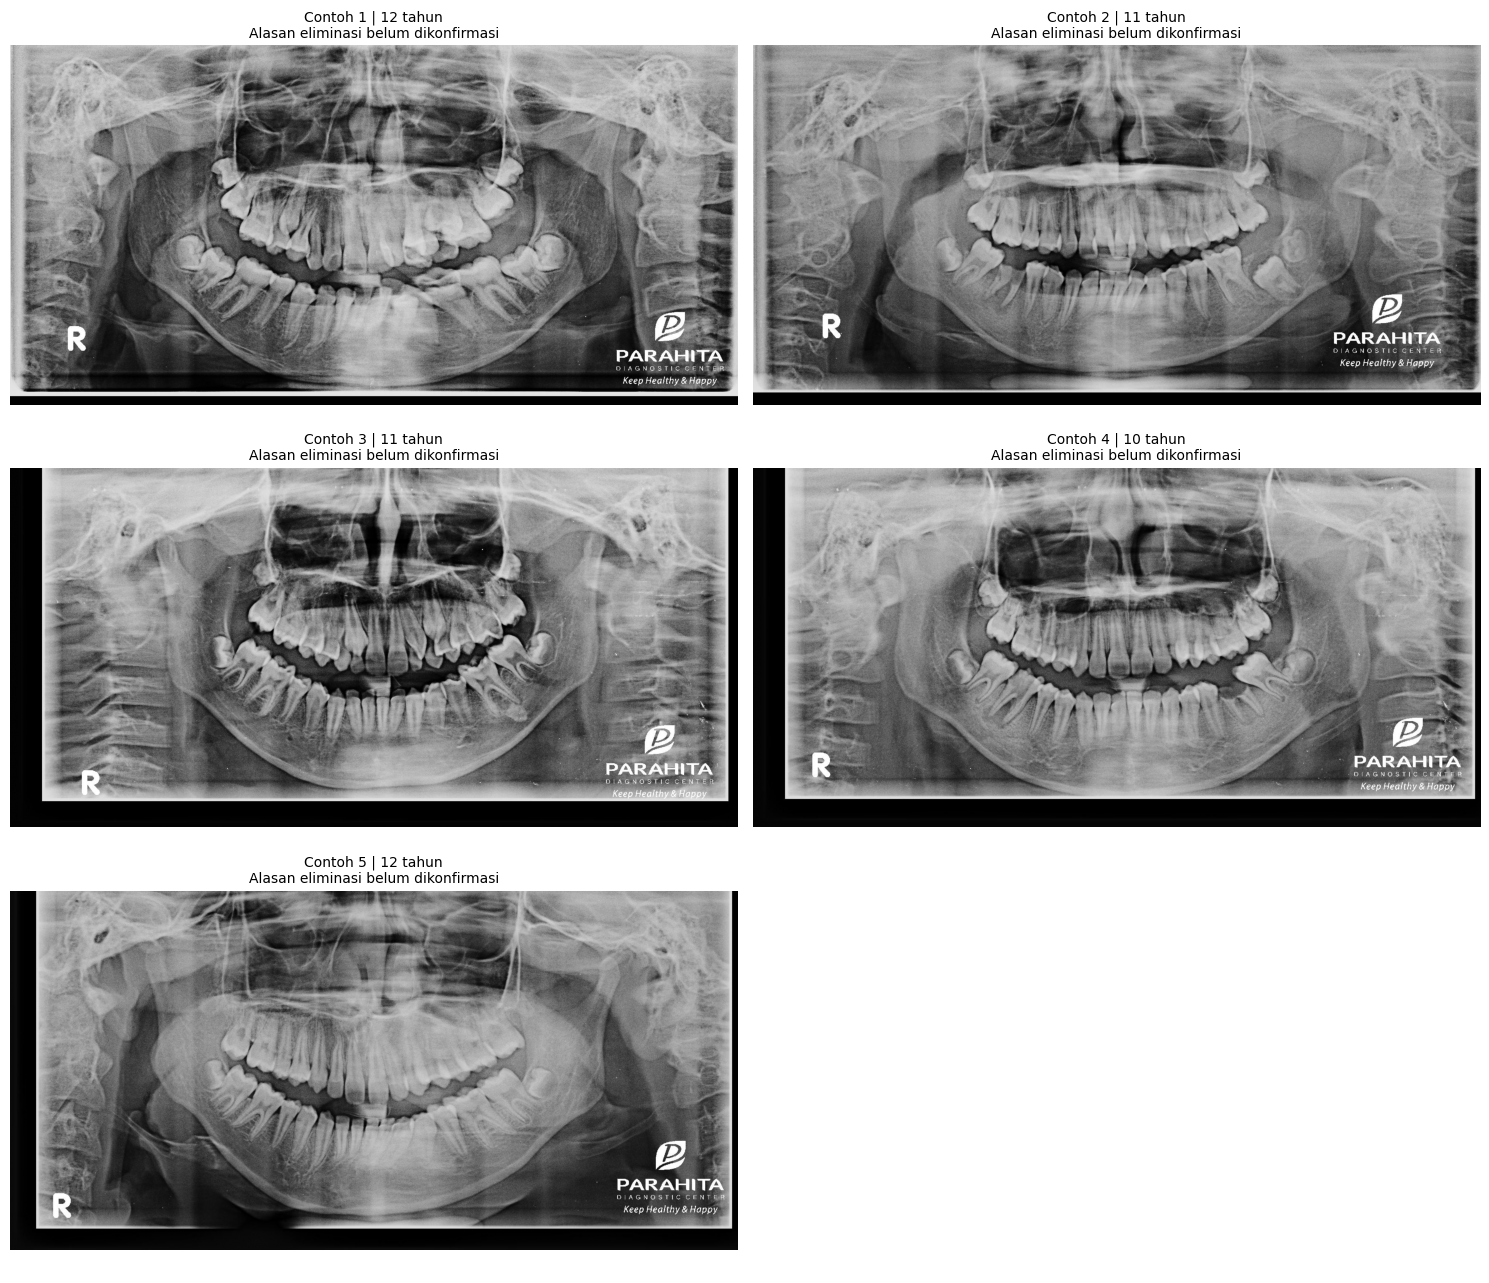

,Contoh,filename,umur,alasan
0,1,"507.PAULINE,AN.12TH.jpg",12 tahun,Alasan eliminasi belum dikonfirmasi
1,2,"1603.DESY,AN.11TH.jpg",11 tahun,Alasan eliminasi belum dikonfirmasi
2,3,341.PUTRA.11 THN-.jpg,11 tahun,Alasan eliminasi belum dikonfirmasi
3,4,1017.celline.10 thn.jpg,10 tahun,Alasan eliminasi belum dikonfirmasi
4,5,985.billa.12 thn.jpg,12 tahun,Alasan eliminasi belum dikonfirmasi



Daftar ini berdasarkan pencocokan nama, termasuk kesetaraan HANA.
Jika ada perubahan nama lain, periksa sebelum menyebutnya eliminasi.
Tidak adanya gigi susu harus berdasarkan review, bukan umur saja.



In [4]:
kunci_final = {kunci_nama(p.name) for p in file_final}

tidak_terpilih = [
    p for p in file_kandidat
    if kunci_nama(p.name) not in kunci_final
]

print("Jumlah kandidat Paramita:", len(file_kandidat))
print("Cocok dengan dataset final:",
      len(file_kandidat) - len(tidak_terpilih))
print("Belum ditemukan di dataset final:", len(tidak_terpilih))

tabel_eliminasi = pd.DataFrame({
    "filename": [p.name for p in tidak_terpilih],
    "umur": [umur_file(p.name) for p in tidak_terpilih],
    "alasan_terkonfirmasi": [""] * len(tidak_terpilih),
    "catatan": [""] * len(tidak_terpilih)
})

with pd.option_context("display.max_rows", None):
    display(tabel_eliminasi)

tabel_eliminasi.to_csv(
    HASIL / "02_daftar_kandidat_tidak_terpilih.csv", index=False
)

# Jika ingin menentukan sendiri lima contoh, isi nama lengkap di sini.
CONTOH_PILIHAN = []
# Contoh:
# CONTOH_PILIHAN = ["0046.ALIFA,AN.11TH.jpg", ...]

# Isi berdasarkan hasil review yang sudah dilakukan.
ALASAN_TERVERIFIKASI = {}
# Contoh:
# ALASAN_TERVERIFIKASI = {
#     "nama_file.jpg": "Detail area target tidak memadai"
# }

if CONTOH_PILIHAN:
    lookup = {p.name: p for p in tidak_terpilih}
    unknown = set(CONTOH_PILIHAN) - set(lookup)
    if unknown:
        raise ValueError(f"Nama tidak ada dalam daftar eliminasi: {unknown}")
    contoh = [lookup[n] for n in CONTOH_PILIHAN[:5]]
else:
    rng = np.random.default_rng(SEED)
    idx = rng.choice(
        len(tidak_terpilih),
        min(5, len(tidak_terpilih)),
        replace=False
    )
    contoh = [tidak_terpilih[i] for i in idx]

if contoh:
    fig, axes = plt.subplots(3, 2, figsize=(15, 13))
    for ax in axes.ravel():
        ax.axis("off")

    ringkasan_contoh = []

    for i, (ax, p) in enumerate(zip(axes.ravel(), contoh), 1):
        with Image.open(p) as im:
            ax.imshow(
                ImageOps.exif_transpose(im).convert("L"),
                cmap="gray", vmin=0, vmax=255
            )

        umur = umur_file(p.name)
        umur_teks = (
            f"{umur:g} tahun" if pd.notna(umur)
            else "Tidak ada keterangan umur"
        )
        alasan = ALASAN_TERVERIFIKASI.get(
            p.name, "Alasan eliminasi belum dikonfirmasi"
        )

        ax.set_title(f"Contoh {i} | {umur_teks}\n{alasan}", fontsize=10)

        ringkasan_contoh.append({
            "Contoh": i,
            "filename": p.name,
            "umur": umur_teks,
            "alasan": alasan
        })

    simpan_grafik("03_lima_contoh_eliminasi")
    display(pd.DataFrame(ringkasan_contoh))

print("""
Daftar ini berdasarkan pencocokan nama, termasuk kesetaraan HANA.
Jika ada perubahan nama lain, periksa sebelum menyebutnya eliminasi.
Tidak adanya gigi susu harus berdasarkan review, bukan umur saja.
""")

Cell A4 — Statistik dasar, usia, dan kualitas 252 citra final

,jumlah_citra,dapat_dibaca,usia_diketahui
source,,,
Kaggle,83,83,0
Paramita 2016–2018,121,121,120
Paramita 2026,48,48,0


,image_id,filename


,count,mean,std,min,25%,50%,75%,max,IQR
width,252.0,1983.905,11.302,1976.000,1976.000,1976.000,2000.000,2000.000,24.000
height,252.0,963.456,15.292,942.000,942.000,969.000,976.000,976.000,34.000
aspect_ratio,252.0,2.060,0.045,2.025,2.025,2.039,2.123,2.123,0.099
brightness,252.0,123.255,12.691,92.229,114.212,123.076,132.033,176.120,17.821
contrast,252.0,59.072,6.383,45.264,55.133,59.588,63.342,77.181,8.209
sharpness_640,252.0,1296.482,883.031,91.675,174.488,1503.520,1931.878,3442.063,1757.390


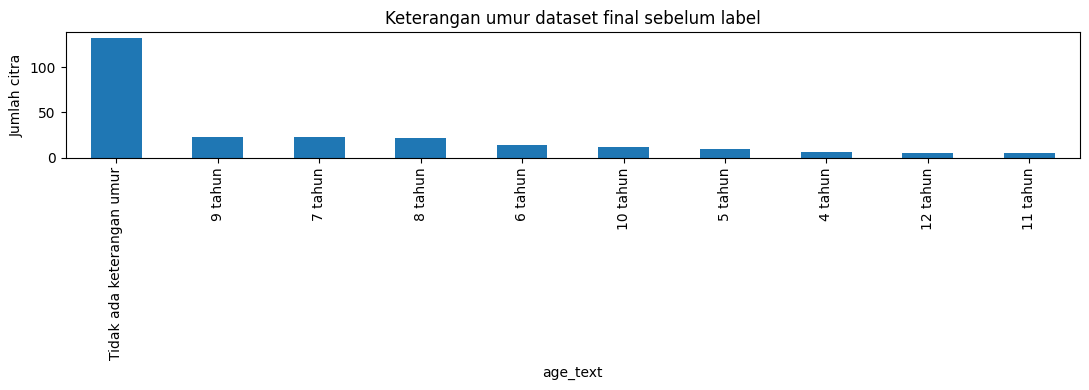

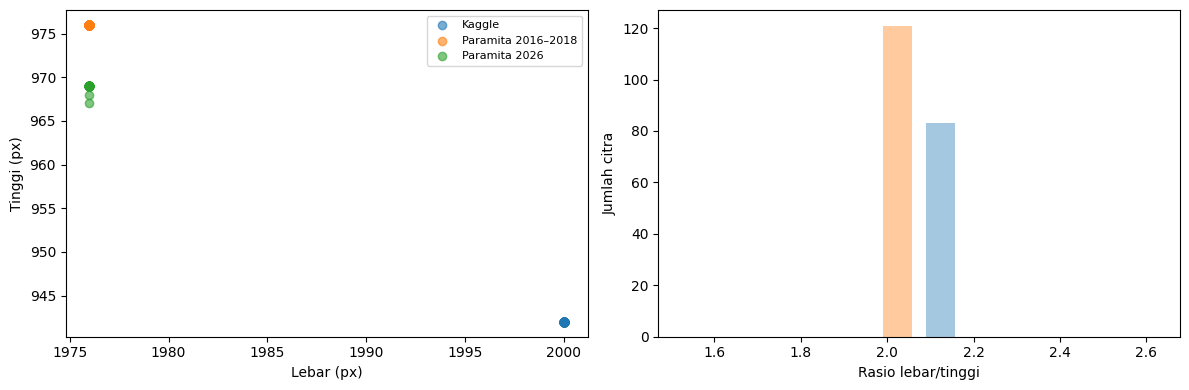

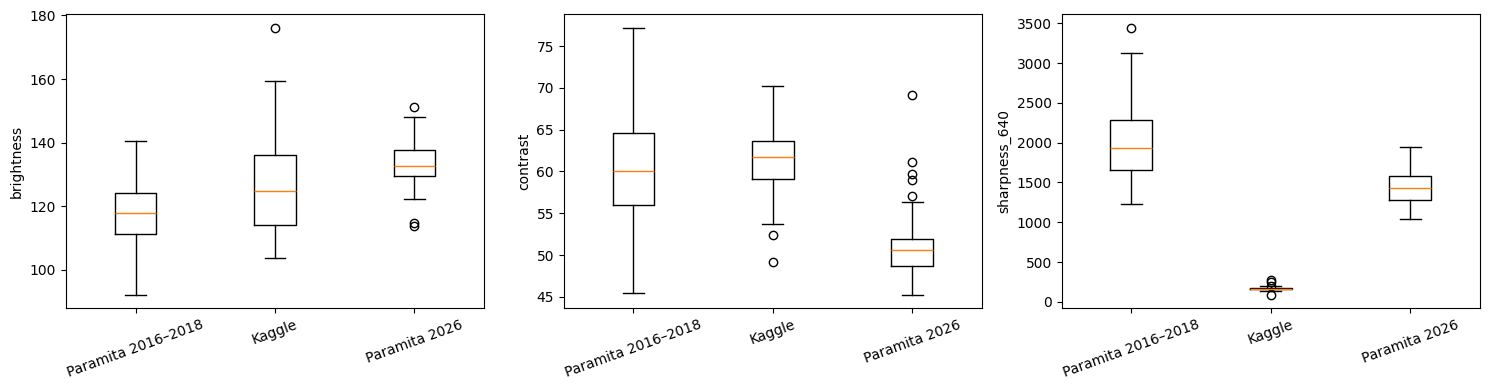


Brightness dan contrast dihitung dari seluruh citra, termasuk latar/logo.
Ketajaman dihitung pada thumbnail lebar 640 px sebagai indikator relatif.
Skor rendah/tinggi tidak otomatis menentukan citra layak atau tidak.
Usia cate dan sulung tidak diisi atau diperkirakan.



In [5]:
metadata = []

for i, p in enumerate(file_final, 1):
    row = {
        "image_id": f"RAW{i:04d}",
        "filename": p.name,
        "source": sumber_final(p.name),
        "age": umur_file(p.name),
        "path": str(p),
        "readable": False
    }

    try:
        with Image.open(p) as im:
            im.load()
            row["mode"] = im.mode
            gray = np.asarray(
                ImageOps.exif_transpose(im).convert("L")
            ).copy()

        h, w = gray.shape
        thumbnail = cv2.resize(
            gray, (640, max(3, round(h * 640 / w)))
        )

        row.update({
            "readable": True,
            "width": w,
            "height": h,
            "aspect_ratio": w / h,
            "brightness": float(gray.mean()),
            "contrast": float(gray.std()),
            "sharpness_640": float(
                cv2.Laplacian(thumbnail, cv2.CV_64F).var()
            )
        })

    except Exception as e:
        row["error"] = str(e)

    metadata.append(row)

meta = pd.DataFrame(metadata)
meta["age_text"] = meta.age.map(
    lambda x: f"{x:g} tahun" if pd.notna(x)
    else "Tidak ada keterangan umur"
)

meta.to_csv(HASIL / "03_metadata_sebelum_label.csv", index=False)

display(meta.groupby("source").agg(
    jumlah_citra=("image_id", "size"),
    dapat_dibaca=("readable", "sum"),
    usia_diketahui=("age", "count")
))

display(meta.loc[
    ~meta.readable, ["image_id", "filename"]
])

variabel = [
    "width", "height", "aspect_ratio",
    "brightness", "contrast", "sharpness_640"
]

statistik = meta[variabel].describe().T
statistik["IQR"] = statistik["75%"] - statistik["25%"]
display(statistik.round(3))
statistik.to_csv(HASIL / "04_statistik_deskriptif_citra.csv")

# Usia, termasuk kategori tidak diketahui.
meta.age_text.value_counts().plot.bar(figsize=(11, 4))
plt.ylabel("Jumlah citra")
plt.title("Keterangan umur dataset final sebelum label")
simpan_grafik("04_distribusi_umur")

# Dimensi gambar.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, g in meta[meta.readable].groupby("source"):
    axes[0].scatter(g.width, g.height, alpha=.6, label=s)
    axes[1].hist(g.aspect_ratio, bins=15, alpha=.4, label=s)

axes[0].set(xlabel="Lebar (px)", ylabel="Tinggi (px)")
axes[1].set(xlabel="Rasio lebar/tinggi", ylabel="Jumlah citra")
axes[0].legend(fontsize=8)
simpan_grafik("05_dimensi_citra")

# Kualitas antarsumber.
sources = list(meta.source.unique())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(
    axes, ["brightness", "contrast", "sharpness_640"]
):
    ax.boxplot([
        meta.loc[
            (meta.source == s) & meta.readable, metric
        ].dropna()
        for s in sources
    ])
    ax.set_xticks(range(1, len(sources)+1), sources, rotation=20)
    ax.set_ylabel(metric)

simpan_grafik("06_kualitas_antarsumber")

print("""
Brightness dan contrast dihitung dari seluruh citra, termasuk latar/logo.
Ketajaman dihitung pada thumbnail lebar 640 px sebagai indikator relatif.
Skor rendah/tinggi tidak otomatis menentukan citra layak atau tidak.
Usia cate dan sulung tidak diisi atau diperkirakan.
""")

# Cell A5 — Duplikat, ringkasan, dan penutup EDA sebelum label

In [6]:
import hashlib

hashes = []

for p in file_final:
    hashes.append({
        "filename": p.name,
        "source": sumber_final(p.name),
        "sha256": hashlib.sha256(p.read_bytes()).hexdigest()
    })

hash_df = pd.DataFrame(hashes)
duplikat = hash_df[
    hash_df.duplicated("sha256", keep=False)
].sort_values("sha256")

display(duplikat)
duplikat.to_csv(HASIL / "05_duplikat_identik.csv", index=False)

ringkasan = pd.DataFrame({
    "Bagian": [
        "Sumber data",
        "Dataset final",
        "Kandidat Paramita",
        "Kandidat belum cocok dengan final",
        "Citra dapat dibaca",
        "Citra tanpa keterangan umur",
        "File dalam kelompok duplikat identik"
    ],
    "Hasil": [
        "Paramita 2016–2018, Paramita 2026, Kaggle",
        len(file_final),
        len(file_kandidat),
        len(tidak_terpilih),
        int(meta.readable.sum()),
        int(meta.age.isna().sum()),
        len(duplikat)
    ]
})

display(ringkasan)
ringkasan.to_csv(HASIL / "06_ringkasan_sebelum_label.csv", index=False)

print("""
NARASI LAPORAN:

Data dikumpulkan dari tiga sumber. Berdasarkan catatan penelitian,
Paramita 2016–2018 menyediakan 2.039 radiograf, Paramita 2026
menyediakan 69 radiograf, dan Kaggle menyediakan 100 citra.

Seleksi menghasilkan dataset final yang komposisinya ditampilkan
pada tabel hasil. Proses seleksi Paramita lama mencakup tahap
kandidat antara sebelum pemilihan final.

EDA sebelum anotasi memeriksa komposisi sumber, keterangan usia,
dimensi, kualitas teknis, dan duplikat citra. Alasan eliminasi
dilaporkan berdasarkan catatan seleksi atau hasil review.

Setelah tahap ini, citra final dianotasi menggunakan bounding box
dan nomor FDI. EDA setelah label dibahas pada bagian berikutnya.
""")

print("Hasil tersimpan di:", HASIL)

,filename,source,sha256


,Bagian,Hasil
0,Sumber data,"Paramita 2016–2018, Paramita 2026, Kaggle"
1,Dataset final,252
2,Kandidat Paramita,171
3,Kandidat belum cocok dengan final,50
4,Citra dapat dibaca,252
5,Citra tanpa keterangan umur,132
6,File dalam kelompok duplikat identik,0



NARASI LAPORAN:

Data dikumpulkan dari tiga sumber. Berdasarkan catatan penelitian,
Paramita 2016–2018 menyediakan 2.039 radiograf, Paramita 2026
menyediakan 69 radiograf, dan Kaggle menyediakan 100 citra.

Seleksi menghasilkan dataset final yang komposisinya ditampilkan
pada tabel hasil. Proses seleksi Paramita lama mencakup tahap
kandidat antara sebelum pemilihan final.

EDA sebelum anotasi memeriksa komposisi sumber, keterangan usia,
dimensi, kualitas teknis, dan duplikat citra. Alasan eliminasi
dilaporkan berdasarkan catatan seleksi atau hasil review.

Setelah tahap ini, citra final dianotasi menggunakan bounding box
dan nomor FDI. EDA setelah label dibahas pada bagian berikutnya.

Hasil tersimpan di: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/hasil_EDA_sebelum_label


# Cell 1 — Drive, pustaka, dan konfigurasi

In [7]:


from pathlib import Path
from collections import Counter
import re, json, hashlib, shutil, zipfile, unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
import cv2
import yaml

from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown


# ============================================================
# 1. TEMUKAN LOKASI FOLDER SEBENARNYA
# ============================================================

def normalisasi_folder(nama):
    nama = unicodedata.normalize("NFKC", nama)
    return " ".join(nama.split()).casefold()


def cari_subfolder(induk, nama):
    if not induk.is_dir():
        raise FileNotFoundError(
            f"Folder induk tidak ditemukan: {induk}"
        )

    cocok = [
        p for p in induk.iterdir()
        if p.is_dir()
        and normalisasi_folder(p.name) == normalisasi_folder(nama)
    ]

    if len(cocok) == 1:
        return cocok[0]

    print(f"\nIsi folder {induk}:")
    for p in sorted(induk.iterdir()):
        print(
            f"{'FOLDER' if p.is_dir() else 'FILE'}: {p.name!r}"
        )

    raise FileNotFoundError(
        f"Folder {nama!r} tidak ditemukan secara unik. "
        "Periksa nama folder pada daftar di atas."
    )


MYDRIVE = Path(os.environ.get("FDI_MYDRIVE", "/content/drive/MyDrive"))
BASE = PROJECT_ROOT

DATASET_FOLDER = RAW_YOLO

CANDIDATES = cari_subfolder(
    BASE, "Data terpilih dari Dental Paramita 11-12"
)


# ============================================================
# 2. TEMUKAN DATA.YAML DAN STRUKTUR YOLO
# ============================================================

yaml_files = sorted(
    p for p in DATASET_FOLDER.rglob("*")
    if p.is_file() and p.name.casefold() == "data.yaml"
)

if len(yaml_files) != 1:
    print("\nIsi tingkat pertama folder dataset:")
    for p in sorted(DATASET_FOLDER.iterdir()):
        print(p.name)

    print("\ndata.yaml yang ditemukan:")
    for p in yaml_files:
        print(p)

    raise FileNotFoundError(
        f"Ditemukan {len(yaml_files)} data.yaml. "
        "Pastikan folder dataset sudah diekstrak dan diunggah lengkap."
    )

YAML_PATH = yaml_files[0]
LABELED = YAML_PATH.parent

TRAIN_FOLDER = cari_subfolder(LABELED, "train")
RAW = cari_subfolder(TRAIN_FOLDER, "images")
LABEL_FOLDER = cari_subfolder(TRAIN_FOLDER, "labels")

# RAW menggunakan kumpulan gambar final yang lengkap.
# Tahap sebelum label hanya membaca gambarnya.


# ============================================================
# 3. BACA DAN VALIDASI PEMETAAN FDI
# ============================================================

with open(YAML_PATH, encoding="utf-8-sig") as f:
    config = yaml.safe_load(f)

if not isinstance(config, dict) or "names" not in config:
    raise ValueError("data.yaml tidak memiliki pemetaan 'names'.")

names = config["names"]

if isinstance(names, dict):
    names = {int(k): str(v) for k, v in names.items()}

    if sorted(names) != list(range(len(names))):
        raise ValueError("Class ID pada data.yaml tidak berurutan dari 0.")

    FDI = [names[k] for k in range(len(names))]
else:
    FDI = list(map(str, names))

expected_FDI = {
    f"{q}{t}" for q in [5, 6, 7, 8] for t in range(1, 6)
}

if len(FDI) != 20 or set(FDI) != expected_FDI:
    raise ValueError(
        f"Pemetaan kelas tidak sesuai 20 FDI gigi susu: {FDI}"
    )


# ============================================================
# 4. KONFIGURASI DAN FOLDER HASIL
# ============================================================

SEED = 42

AGE_OVERRIDES = {}  # {"nama_file.jpg": 6}
PATIENT_IDS = {}    # {"nama_file.jpg": "P001"}

EXPORT_DATASET = False

EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

RUN_ID = pd.Timestamp.now(
    tz="Asia/Jakarta"
).strftime("%Y%m%d_%H%M%S")

OUT = EDA_HOME / f"EDA_FDI_lengkap_{RUN_ID}"

# Dibuat setelah lokasi input dan data.yaml berhasil divalidasi.
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


# ============================================================
# 5. FUNGSI UNTUK CELL BERIKUTNYA
# ============================================================

def title(text):
    display(Markdown("### " + text))


def saveplot(name):
    plt.tight_layout()
    plt.savefig(
        OUT / f"{name}.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def image_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Folder gambar tidak ditemukan: {folder}"
        )

    return sorted(
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in EXTENSIONS
    )


def source(name):
    name = name.strip().casefold()

    if name.startswith("cate"):
        return "Kaggle"

    if name.startswith("sulung"):
        return "Paramita 2026"

    return "Paramita 2016–2018"


def name_key(name):
    s = re.split(r"\.rf\.", Path(name).stem.lower())[0]
    s = re.sub(
        r"_(jpg|jpeg|png|bmp|tif|tiff|webp)$", "", s
    )
    s = re.sub(r"[^a-z0-9]", "", s)

    return (
        "345hanaan4th"
        if s == "345hanaan4th1"
        else s
    )


def get_age(name):
    if name in AGE_OVERRIDES:
        return float(AGE_OVERRIDES[name])

    if source(name) != "Paramita 2016–2018":
        return np.nan

    matches = set(re.findall(
        r"(\d+(?:[.,]\d+)?)[ _-]*TH(?:N)?(?=[_. -]|$)",
        name,
        re.I
    ))

    if len(matches) == 1:
        return float(
            next(iter(matches)).replace(",", ".")
        )

    return np.nan


# ============================================================
# 6. KONFIRMASI
# ============================================================

print("Konfigurasi berhasil.")
print("BASE:", BASE)
print("Dataset berlabel:", LABELED)
print("data.yaml:", YAML_PATH)
print("Gambar final:", RAW)
print("Folder label:", LABEL_FOLDER)
print("Jumlah gambar final:", len(image_files(RAW)))
print("Folder hasil:", OUT)

display(pd.DataFrame({
    "class_id_YOLO": range(len(FDI)),
    "FDI": FDI
}))

Konfigurasi berhasil.
BASE: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi
Dataset berlabel: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11
data.yaml: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11/data.yaml
Gambar final: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11/train/images
Folder label: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11/train/labels
Jumlah gambar final: 252
Folder hasil: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/EDA_FDI_lengkap_20261031_140236


,class_id_YOLO,FDI
0,0,51
1,1,52
2,2,53
3,3,54
4,4,55
5,5,61
6,6,62
7,7,63
8,8,64
9,9,65


# Cell 2 — Deskripsi dataset, seleksi, dan lima contoh eliminasi
Jumlah sumber awal adalah catatan penelitian Anda. Jumlah kandidat dan final dihitung dari folder.

,Sumber,Data awal menurut catatan,Kandidat antara,Final sebelum label
0,Paramita 2016–2018,2039,171.0,121
1,Paramita 2026,69,NaN,48
2,Kaggle,100,NaN,83


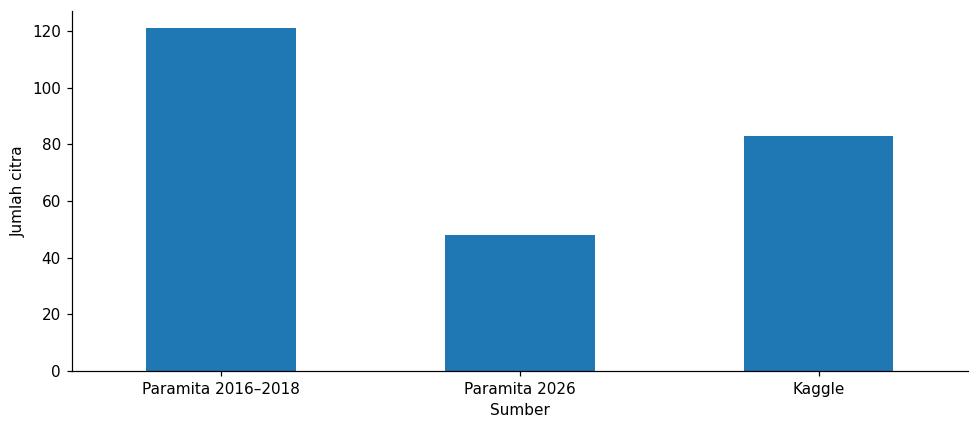

Kandidat Paramita: 171
Tidak cocok dengan nama dataset final: 50


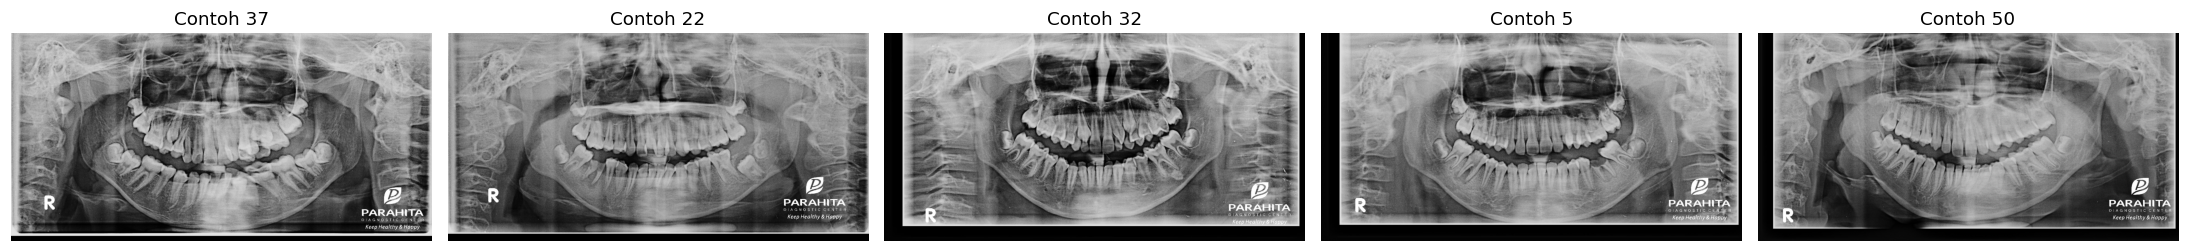

,filename
0,"507.PAULINE,AN.12TH.jpg"
1,"1603.DESY,AN.11TH.jpg"
2,341.PUTRA.11 THN-.jpg
3,1017.celline.10 thn.jpg
4,985.billa.12 thn.jpg



Alasan seperti tidak terdapat gigi susu atau kualitas tidak memadai
harus dikonfirmasi melalui review. Ketidakcocokan nama juga dapat
disebabkan perubahan nama file.



In [8]:
raw_files = image_files(RAW)
candidate_files = image_files(CANDIDATES)
raw_counts = Counter(source(p.name) for p in raw_files)

source_order = ["Paramita 2016–2018", "Paramita 2026", "Kaggle"]

selection = pd.DataFrame({
    "Sumber": source_order,
    "Data awal menurut catatan": [2039, 69, 100],
    "Kandidat antara": [len(candidate_files), np.nan, np.nan],
    "Final sebelum label": [raw_counts[s] for s in source_order]
})
display(selection)
selection.to_csv(OUT / "01_alur_seleksi.csv", index=False)

selection.plot.bar(
    x="Sumber", y="Final sebelum label",
    legend=False, rot=0, figsize=(9, 4)
)
plt.ylabel("Jumlah citra")
saveplot("01_komposisi_sumber")

final_keys = {name_key(p.name) for p in raw_files}
not_selected = [
    p for p in candidate_files if name_key(p.name) not in final_keys
]

print("Kandidat Paramita:", len(candidate_files))
print("Tidak cocok dengan nama dataset final:", len(not_selected))

elimination_review = pd.DataFrame({
    "filename": [p.name for p in not_selected],
    "alasan_terkonfirmasi": [""] * len(not_selected),
    "penilai": [""] * len(not_selected),
})
elimination_review.to_csv(
    OUT / "02_review_eliminasi.csv", index=False
)

if not_selected:
    rng = np.random.default_rng(SEED)
    ids = rng.choice(
        len(not_selected), min(5, len(not_selected)), replace=False
    )
    fig, axes = plt.subplots(
        1, len(ids), figsize=(4 * len(ids), 4), squeeze=False
    )

    for ax, i in zip(axes.ravel(), ids):
        p = not_selected[i]
        with Image.open(p) as im:
            ax.imshow(
                ImageOps.exif_transpose(im).convert("L"),
                cmap="gray", vmin=0, vmax=255
            )
        ax.set_title(f"Contoh {i + 1}")
        ax.axis("off")

    saveplot("02_contoh_tidak_masuk_final")
    display(pd.DataFrame({
        "filename": [not_selected[i].name for i in ids]
    }))

print("""
Alasan seperti tidak terdapat gigi susu atau kualitas tidak memadai
harus dikonfirmasi melalui review. Ketidakcocokan nama juga dapat
disebabkan perubahan nama file.
""")

# Cell 3 — Audit citra dan anotasi
Audit memeriksa file rusak, pasangan label, format YOLO, kelas, koordinat, dan label kosong.

In [9]:
paths = sorted(
    p for p in image_files(LABELED)
    if p.parent.name == "images"
)

rows, box_rows, error_rows = [], [], []

for i, p in enumerate(paths, 1):
    uid = f"IMG{i:04d}"
    lp = p.parent.parent / "labels" / f"{p.stem}.txt"

    row = {
        "image_id": uid,
        "filename": p.name,
        "path": str(p),
        "label_path": str(lp),
        "source": source(p.name),
        "age": get_age(p.name),
        "readable": False,
        "n_boxes": 0,
        "label_exists": lp.exists(),
    }

    try:
        data = p.read_bytes()
        row["file_sha256"] = hashlib.sha256(data).hexdigest()
        row["file_kb"] = len(data) / 1024

        with Image.open(p) as im:
            im.load()
            gray = np.asarray(im.convert("L")).copy()
            row["mode"] = im.mode
            row["orientation"] = int(im.getexif().get(274, 1))

        h, w = gray.shape
        small = cv2.resize(
            gray, (640, max(3, round(h * 640 / w)))
        )
        thumb = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)

        row.update({
            "readable": True,
            "width": w,
            "height": h,
            "image_aspect": w / h,
            "brightness": float(gray.mean()),
            "contrast": float(gray.std()),
            "sharpness_640": float(
                cv2.Laplacian(small, cv2.CV_64F).var()
            ),
            "dark_pct": float((gray <= 5).mean() * 100),
            "bright_pct": float((gray >= 250).mean() * 100),
            "pixel_hash": hashlib.sha256(
                f"{w}x{h}|".encode() + gray.tobytes()
            ).hexdigest(),
            "dhash": "".join(
                "1" if v else "0"
                for v in (thumb[:, 1:] > thumb[:, :-1]).ravel()
            )
        })
    except Exception as e:
        error_rows.append({
            "filename": p.name, "issue": "gambar_rusak",
            "detail": str(e)
        })

    if not lp.exists():
        error_rows.append({
            "filename": p.name, "issue": "label_tidak_ada"
        })
    else:
        for line_no, line in enumerate(lp.read_text().splitlines(), 1):
            if not line.strip():
                continue

            try:
                values = list(map(float, line.split()))
                if len(values) != 5 or not np.isfinite(values).all():
                    raise ValueError("Harus lima angka finite")

                c, x, y, bw, bh = values

                if not c.is_integer() or not 0 <= c < len(FDI):
                    raise ValueError("Class ID tidak valid")
                if not (
                    0 <= x <= 1 and 0 <= y <= 1
                    and 0 < bw <= 1 and 0 < bh <= 1
                ):
                    raise ValueError("Koordinat tidak valid")
                if (
                    min(x - bw/2, y - bh/2) < -1e-5
                    or max(x + bw/2, y + bh/2) > 1 + 1e-5
                ):
                    raise ValueError("Bounding box di luar citra")

                box_rows.append({
                    "image_id": uid, "line": line_no,
                    "class_id": int(c), "FDI": FDI[int(c)],
                    "x": x, "y": y, "w": bw, "h": bh,
                    "relative_area": bw * bh,
                    "box_aspect": bw / bh,
                })
                row["n_boxes"] += 1

            except Exception as e:
                error_rows.append({
                    "filename": p.name,
                    "issue": "label_invalid",
                    "line": line_no,
                    "detail": str(e)
                })

    rows.append(row)

df = pd.DataFrame(rows)
ann = pd.DataFrame(box_rows)
audit = pd.DataFrame(
    error_rows, columns=["filename", "issue", "line", "detail"]
)

assert len(df) and len(ann), "Dataset atau anotasi valid tidak ditemukan."

ann = ann.merge(
    df[["image_id", "source", "age", "width", "height"]],
    on="image_id"
)
ann["box_width_px"] = ann.w * ann.width
ann["box_height_px"] = ann.h * ann.height
ann["box_area_px"] = ann.box_width_px * ann.box_height_px

df["n_unique_FDI"] = df.image_id.map(
    ann.groupby("image_id").FDI.nunique()
).fillna(0).astype(int)

df["age_text"] = df.age.map(
    lambda a: f"{a:g} tahun" if pd.notna(a)
    else "Tidak ada keterangan umur"
)

repeated = (
    ann.groupby(["image_id", "FDI"]).size()
    .rename("jumlah").reset_index()
)
repeated = repeated[repeated.jumlah > 1].merge(
    df[["image_id", "filename"]], on="image_id"
)

duplicate_boxes = ann[
    ann.duplicated(["image_id", "class_id", "x", "y", "w", "h"], keep=False)
]

display(audit)
display(df[df.n_boxes == 0][["image_id", "filename", "label_exists"]])
display(repeated)

df.to_csv(OUT / "03_metadata.csv", index=False)
ann.to_csv(OUT / "04_anotasi.csv", index=False)
audit.to_csv(OUT / "05_audit_teknis.csv", index=False)
repeated.to_csv(OUT / "06_FDI_berulang.csv", index=False)
duplicate_boxes.to_csv(OUT / "07_kotak_identik.csv", index=False)

# Kesesuaian data sebelum dan setelah anotasi.
raw_keys = {name_key(p.name) for p in raw_files}
label_keys = {name_key(n) for n in df.filename}
print("Nama final mentah belum cocok dengan dataset berlabel:",
      len(raw_keys - label_keys))
print("Nama dataset berlabel belum cocok dengan final mentah:",
      len(label_keys - raw_keys))

if len(audit):
    raise ValueError(
        "Ada masalah teknis. Periksa tabel audit sebelum melanjutkan."
    )

,filename,issue,line,detail


,image_id,filename,label_exists


,image_id,FDI,jumlah,filename
0,IMG0006,53,2,0147-diky-an-9-thn_jpg.rf.998a4a45f57021ec121d...
1,IMG0014,83,2,0469-ANINDYA-AN-6TH_jpg.rf.eeefc80b698e75e02cd...
2,IMG0017,64,2,1004-AMIRA-AN-6TH_jpg.rf.1e764a199cd8bafbd1334...
3,IMG0017,65,2,1004-AMIRA-AN-6TH_jpg.rf.1e764a199cd8bafbd1334...
4,IMG0028,55,2,1246-BARA-AN-4TH_jpg.rf.f30e7f314ac85964fec00d...
5,IMG0035,55,2,1332-shafa-4-thn_jpg.rf.2e8d1c1ab73a0ebd437d7b...
6,IMG0043,55,2,1453-PRATAMA-7TH_jpg.rf.58115a4990f30ba210dd32...
7,IMG0043,63,2,1453-PRATAMA-7TH_jpg.rf.58115a4990f30ba210dd32...
8,IMG0043,65,2,1453-PRATAMA-7TH_jpg.rf.58115a4990f30ba210dd32...
9,IMG0047,64,2,1476-IFFA-5TH_jpg.rf.fc0ac46957944ba5343c68894...


Nama final mentah belum cocok dengan dataset berlabel: 0
Nama dataset berlabel belum cocok dengan final mentah: 0


# Cell 4 — Deskripsi dataset dan statistik deskriptif
Dua unit analisis dipisahkan: per citra dan per objek/anotasi.

In [10]:
title("Deskripsi dataset")

description = pd.DataFrame({
    "Komponen": [
        "Tujuan", "Jenis data", "Jumlah citra",
        "Jumlah anotasi", "Jumlah kelas", "Kelas FDI",
        "Usia diketahui", "Usia tanpa keterangan",
        "Citra dengan label", "Citra tanpa anotasi"
    ],
    "Keterangan": [
        "Deteksi dan enumerasi gigi susu berdasarkan FDI; cakupan 1–12 tahun",
        "Radiograf dan anotasi bounding box YOLO",
        len(df), len(ann), len(FDI), ", ".join(FDI),
        int(df.age.notna().sum()), int(df.age.isna().sum()),
        int((df.n_boxes > 0).sum()), int((df.n_boxes == 0).sum())
    ]
})
display(description)
description.to_csv(OUT / "08_deskripsi_dataset.csv", index=False)

def descriptive(data, columns):
    result = data[columns].describe(
        percentiles=[.25, .5, .75]
    ).T.rename(columns={"50%": "median", "25%": "Q1", "75%": "Q3"})
    result["IQR"] = result.Q3 - result.Q1
    return result

image_stats = descriptive(df, [
    "width", "height", "image_aspect",
    "brightness", "contrast", "sharpness_640",
    "n_boxes", "n_unique_FDI"
])
object_stats = descriptive(ann, [
    "box_width_px", "box_height_px", "box_area_px",
    "relative_area", "box_aspect"
])

title("Statistik per citra")
display(image_stats.round(3))

title("Statistik per anotasi")
display(object_stats.round(3))

image_stats.to_csv(OUT / "09_statistik_per_citra.csv")
object_stats.to_csv(OUT / "10_statistik_per_anotasi.csv")

display(df.groupby("source").agg(
    citra=("image_id", "size"),
    anotasi=("n_boxes", "sum"),
    median_anotasi=("n_boxes", "median"),
    usia_diketahui=("age", "count")
))

### Deskripsi dataset

,Komponen,Keterangan
0,Tujuan,Deteksi dan enumerasi gigi susu berdasarkan FD...
1,Jenis data,Radiograf dan anotasi bounding box YOLO
2,Jumlah citra,252
3,Jumlah anotasi,3343
4,Jumlah kelas,20
5,Kelas FDI,"51, 52, 53, 54, 55, 61, 62, 63, 64, 65, 71, 72..."
6,Usia diketahui,120
7,Usia tanpa keterangan,132
8,Citra dengan label,252
9,Citra tanpa anotasi,0


### Statistik per citra

,count,mean,std,min,Q1,median,Q3,max,IQR
width,252.0,1983.905,11.302,1976.000,1976.000,1976.000,2000.000,2000.000,24.000
height,252.0,963.456,15.292,942.000,942.000,969.000,976.000,976.000,34.000
image_aspect,252.0,2.060,0.045,2.025,2.025,2.039,2.123,2.123,0.099
brightness,252.0,123.255,12.691,92.229,114.212,123.076,132.033,176.120,17.821
contrast,252.0,59.072,6.383,45.264,55.133,59.588,63.342,77.181,8.209
sharpness_640,252.0,1296.482,883.031,91.675,174.488,1503.520,1931.878,3442.063,1757.390
n_boxes,252.0,13.266,5.498,1.000,10.000,13.000,19.000,20.000,9.000
n_unique_FDI,252.0,13.115,5.495,1.000,10.000,13.000,19.000,20.000,9.000


### Statistik per anotasi

,count,mean,std,min,Q1,median,Q3,max,IQR
box_width_px,3343.0,69.239,26.522,23.890,49.440,61.900,85.180,179.400,35.740
box_height_px,3343.0,104.675,26.485,28.000,86.335,103.260,121.660,195.470,35.325
box_area_px,3343.0,7533.778,4249.287,1097.046,4597.453,6444.849,9354.153,33181.824,4756.700
relative_area,3343.0,0.004,0.002,0.001,0.002,0.003,0.005,0.018,0.003
box_aspect,3343.0,0.330,0.123,0.111,0.235,0.314,0.400,1.852,0.165


,citra,anotasi,median_anotasi,usia_diketahui
source,,,,
Kaggle,83,1326,18.0,0
Paramita 2016–2018,121,1376,12.0,120
Paramita 2026,48,641,12.5,0


# Cell 5 — Distribusi usia, FDI, dan jumlah label setiap citra

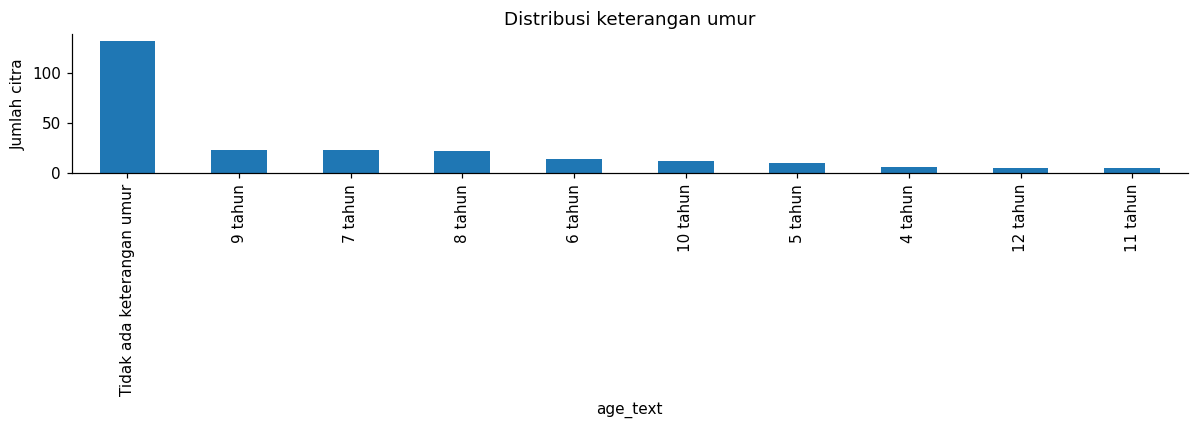

,jumlah_anotasi,jumlah_citra_memuat_FDI
FDI,,
51,91,91
52,127,125
53,225,221
54,211,208
55,237,232
61,89,89
62,129,127
63,221,219
64,208,205


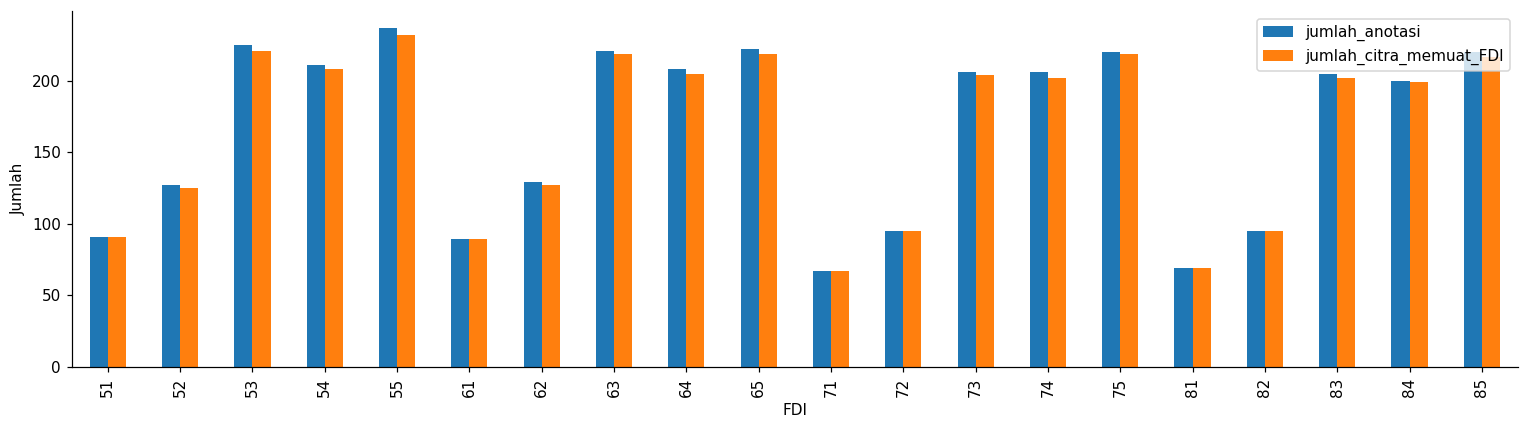

,image_id,filename,source,age_text,n_boxes,n_unique_FDI
0,IMG0001,0031-BEAUTY-AN-5TH_jpg.rf.4030e6326d4102644a02...,Paramita 2016–2018,5 tahun,18,18
1,IMG0002,0049-LINTANG-AN-8TH_jpg.rf.3b93a454c0020be9843...,Paramita 2016–2018,8 tahun,12,12
2,IMG0003,0056-MICHAEL-AN-9TH_jpg.rf.a01f64b1743841e6bc9...,Paramita 2016–2018,9 tahun,12,12
3,IMG0004,0061-ALTHAMIS-AN-7TH_jpg.rf.3d1d6a685cb7c981b3...,Paramita 2016–2018,7 tahun,15,15
4,IMG0005,0107-SHEVA-AN-7TH_jpg.rf.b35a0dbaa51557ea916d8...,Paramita 2016–2018,7 tahun,14,14
...,...,...,...,...,...,...
247,IMG0248,sulung5_jpg.rf.921ef00b1b69f3af95722870ab77fa1...,Paramita 2026,Tidak ada keterangan umur,20,20
248,IMG0249,sulung6_jpg.rf.0dbf554d129db2ced31b3bf514297d7...,Paramita 2026,Tidak ada keterangan umur,10,10
249,IMG0250,sulung7_jpg.rf.6276753c880fca658b950a6d736b589...,Paramita 2026,Tidak ada keterangan umur,20,20
250,IMG0251,sulung8_jpg.rf.e16b4051f39a4c996e2f74e06e0ac3d...,Paramita 2026,Tidak ada keterangan umur,5,5


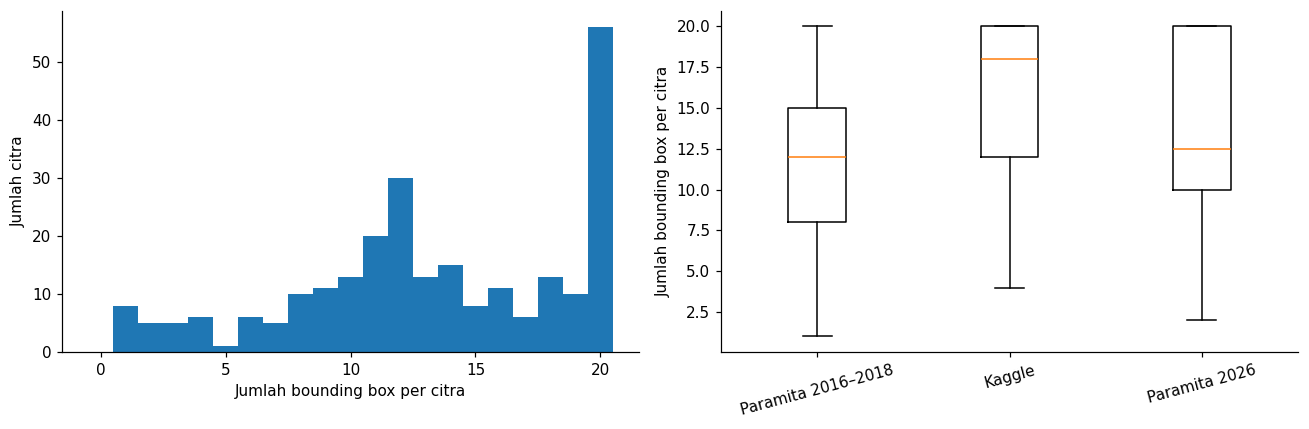

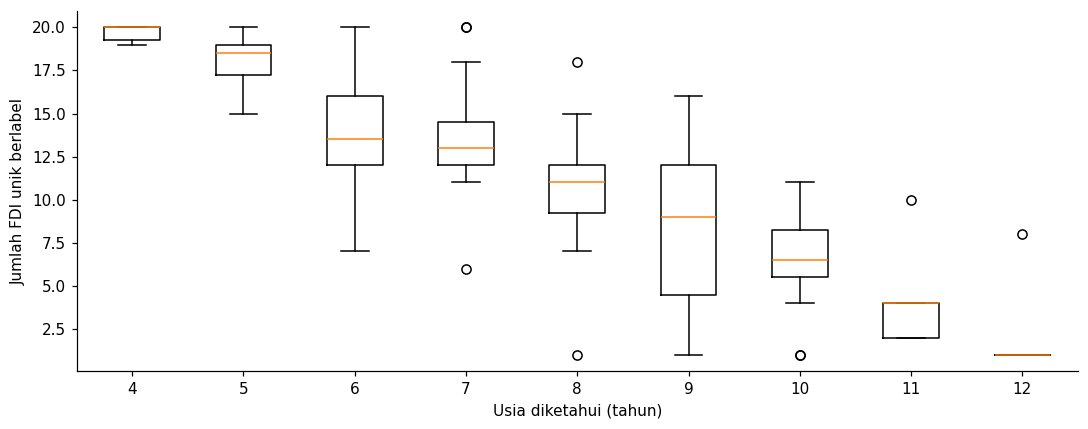

FDI tidak berlabel belum tentu berarti gigi tidak ada.


In [11]:
# Usia diketahui dan tidak diketahui.
df.age_text.value_counts().plot.bar(figsize=(11, 4))
plt.ylabel("Jumlah citra")
plt.title("Distribusi keterangan umur")
saveplot("03_distribusi_umur")

# Frekuensi objek dan jumlah citra yang memuat setiap FDI.
fdi_frequency = ann.FDI.value_counts().reindex(FDI, fill_value=0)
fdi_presence = (
    ann.drop_duplicates(["image_id", "FDI"])
    .FDI.value_counts().reindex(FDI, fill_value=0)
)

fdi_table = pd.DataFrame({
    "jumlah_anotasi": fdi_frequency,
    "jumlah_citra_memuat_FDI": fdi_presence,
})
display(fdi_table)
fdi_table.to_csv(OUT / "11_distribusi_FDI.csv")

fdi_table.plot.bar(figsize=(14, 4))
plt.ylabel("Jumlah")
saveplot("04_distribusi_FDI")

# Jumlah label setiap gambar: tabel lengkap.
per_image = df[[
    "image_id", "filename", "source", "age_text",
    "n_boxes", "n_unique_FDI"
]].copy()
display(per_image)
per_image.to_csv(OUT / "12_jumlah_label_setiap_citra.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(
    df.n_boxes, bins=np.arange(df.n_boxes.max() + 2) - .5
)
axes[0].set(xlabel="Jumlah bounding box per citra", ylabel="Jumlah citra")

sources = list(df.source.unique())
axes[1].boxplot([
    df.loc[df.source == s, "n_boxes"] for s in sources
])
axes[1].set_xticks(range(1, len(sources)+1), sources, rotation=15)
axes[1].set_ylabel("Jumlah bounding box per citra")
saveplot("05_distribusi_jumlah_label")

# Jumlah FDI unik menurut usia yang diketahui.
known = df.dropna(subset=["age"])
if len(known):
    ages = sorted(known.age.unique())
    plt.figure(figsize=(10, 4))
    plt.boxplot([
        known.loc[known.age == a, "n_unique_FDI"] for a in ages
    ])
    plt.xticks(range(1, len(ages)+1), [f"{a:g}" for a in ages])
    plt.xlabel("Usia diketahui (tahun)")
    plt.ylabel("Jumlah FDI unik berlabel")
    saveplot("06_FDI_unik_menurut_usia")

print("FDI tidak berlabel belum tentu berarti gigi tidak ada.")

# Cell 6 — Ukuran, bentuk, dan posisi label

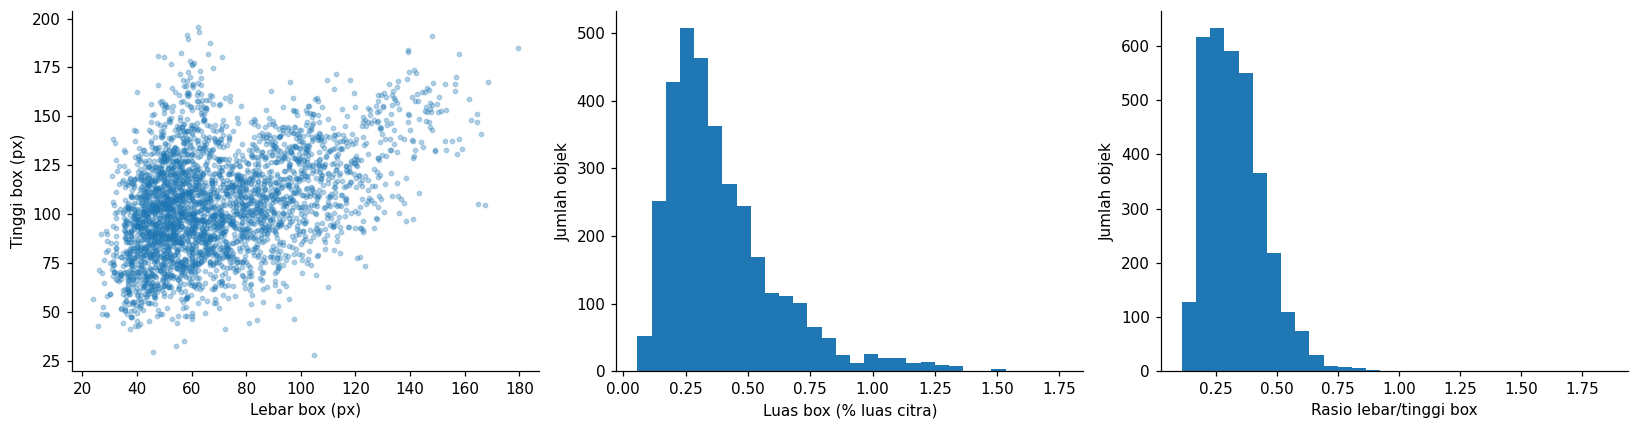

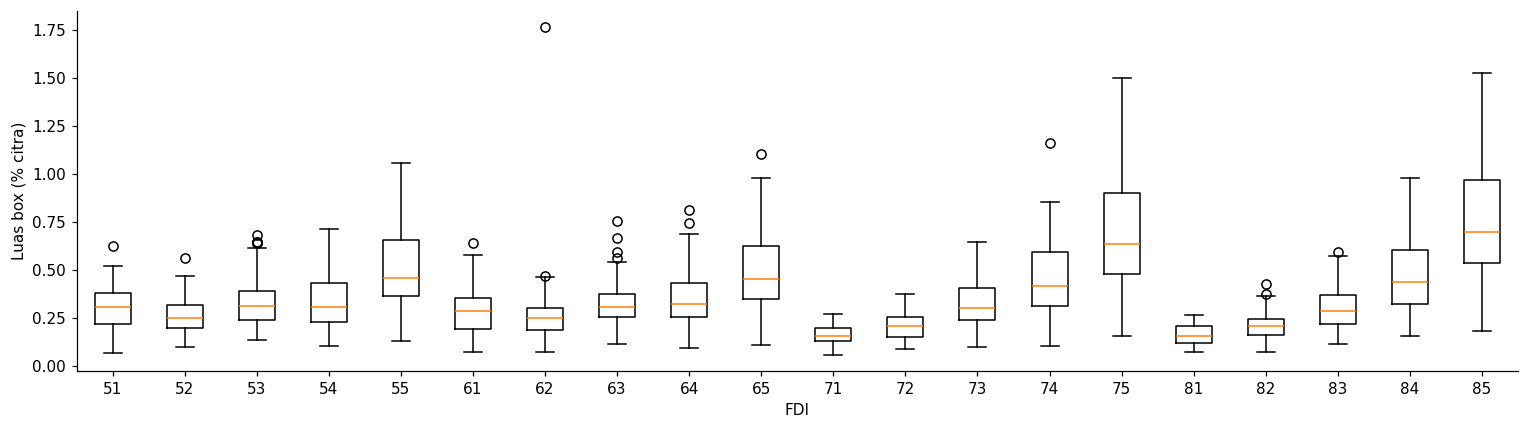

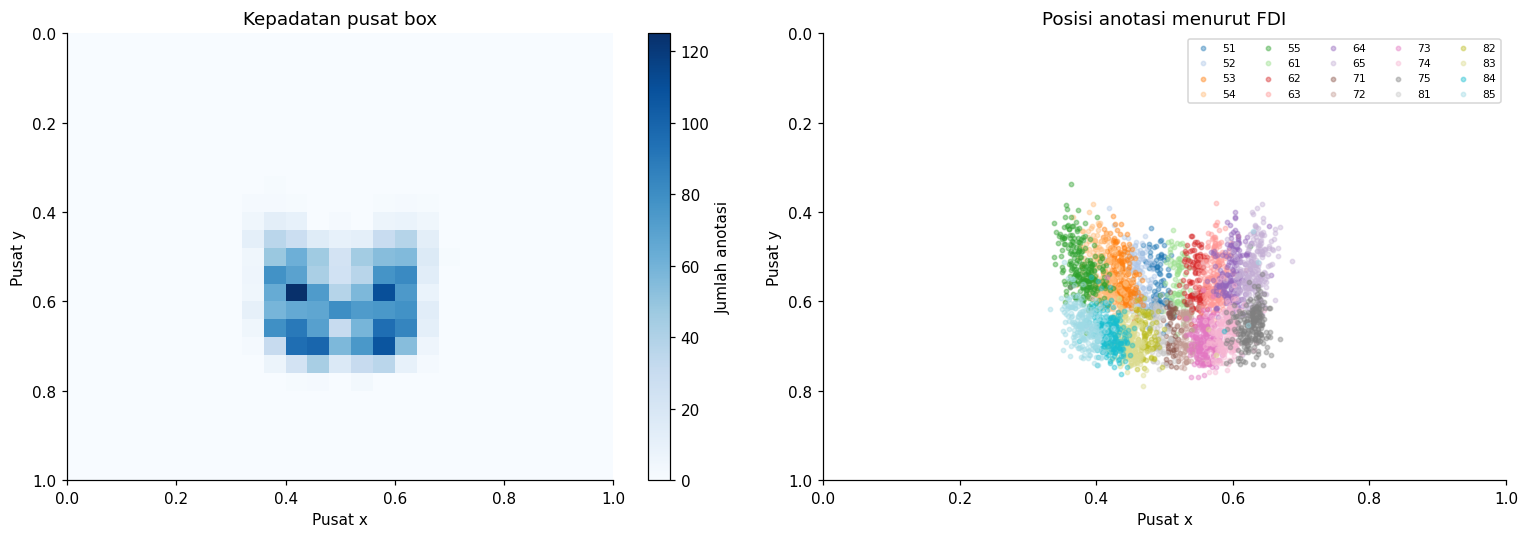

,box_width_px,box_height_px,relative_area,box_aspect
FDI,,,,
51,56.380,102.130,0.003061,0.269258
52,49.900,95.830,0.002511,0.253776
53,56.190,108.790,0.003132,0.239385
54,65.000,92.910,0.003037,0.328153
55,84.000,108.400,0.004553,0.375720
61,54.010,102.700,0.002849,0.258079
62,48.850,94.520,0.002477,0.242496
63,54.170,111.430,0.003058,0.227836
64,68.380,93.710,0.003216,0.335319


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(
    ann.box_width_px, ann.box_height_px, s=8, alpha=.3
)
axes[0].set(xlabel="Lebar box (px)", ylabel="Tinggi box (px)")

axes[1].hist(ann.relative_area * 100, bins=30)
axes[1].set(xlabel="Luas box (% luas citra)", ylabel="Jumlah objek")

axes[2].hist(ann.box_aspect, bins=30)
axes[2].set(xlabel="Rasio lebar/tinggi box", ylabel="Jumlah objek")

saveplot("07_ukuran_bentuk_label")

# Luas relatif per FDI.
plt.figure(figsize=(14, 4))
plt.boxplot([
    ann.loc[ann.FDI == f, "relative_area"] * 100 for f in FDI
])
plt.xticks(range(1, 21), FDI)
plt.xlabel("FDI")
plt.ylabel("Luas box (% citra)")
saveplot("08_luas_box_per_FDI")

# Posisi seluruh objek dan posisi menurut FDI.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

heat = axes[0].hist2d(
    ann.x, ann.y, bins=25, range=[[0, 1], [0, 1]], cmap="Blues"
)
axes[0].invert_yaxis()
axes[0].set(xlabel="Pusat x", ylabel="Pusat y", title="Kepadatan pusat box")
fig.colorbar(heat[3], ax=axes[0], label="Jumlah anotasi")

colors = plt.get_cmap("tab20")
for i, fdi in enumerate(FDI):
    g = ann[ann.FDI == fdi]
    axes[1].scatter(g.x, g.y, s=8, alpha=.4, color=colors(i), label=fdi)

axes[1].set(
    xlim=(0, 1), ylim=(1, 0),
    xlabel="Pusat x", ylabel="Pusat y",
    title="Posisi anotasi menurut FDI"
)
axes[1].legend(ncol=5, fontsize=7)
saveplot("09_posisi_label")

display(ann.groupby("FDI")[
    ["box_width_px", "box_height_px", "relative_area", "box_aspect"]
].median().reindex(FDI))

# Cell 7 — Hubungan antarvariabel

,age,brightness,contrast,sharpness_640,n_boxes,n_unique_FDI,median_box_area
age,1.00,-0.27,-0.08,0.10,-0.79,-0.78,-0.02
brightness,-0.27,1.00,-0.44,-0.27,0.19,0.18,0.07
contrast,-0.08,-0.44,1.00,-0.07,0.09,0.10,0.02
sharpness_640,0.10,-0.27,-0.07,1.00,-0.35,-0.36,-0.62
n_boxes,-0.79,0.19,0.09,-0.35,1.00,0.99,0.15
n_unique_FDI,-0.78,0.18,0.10,-0.36,0.99,1.00,0.16
median_box_area,-0.02,0.07,0.02,-0.62,0.15,0.16,1.00


,age,brightness,contrast,sharpness_640,n_boxes,n_unique_FDI,median_box_area
age,120,120,120,120,120,120,120
brightness,120,252,252,252,252,252,252
contrast,120,252,252,252,252,252,252
sharpness_640,120,252,252,252,252,252,252
n_boxes,120,252,252,252,252,252,252
n_unique_FDI,120,252,252,252,252,252,252
median_box_area,120,252,252,252,252,252,252


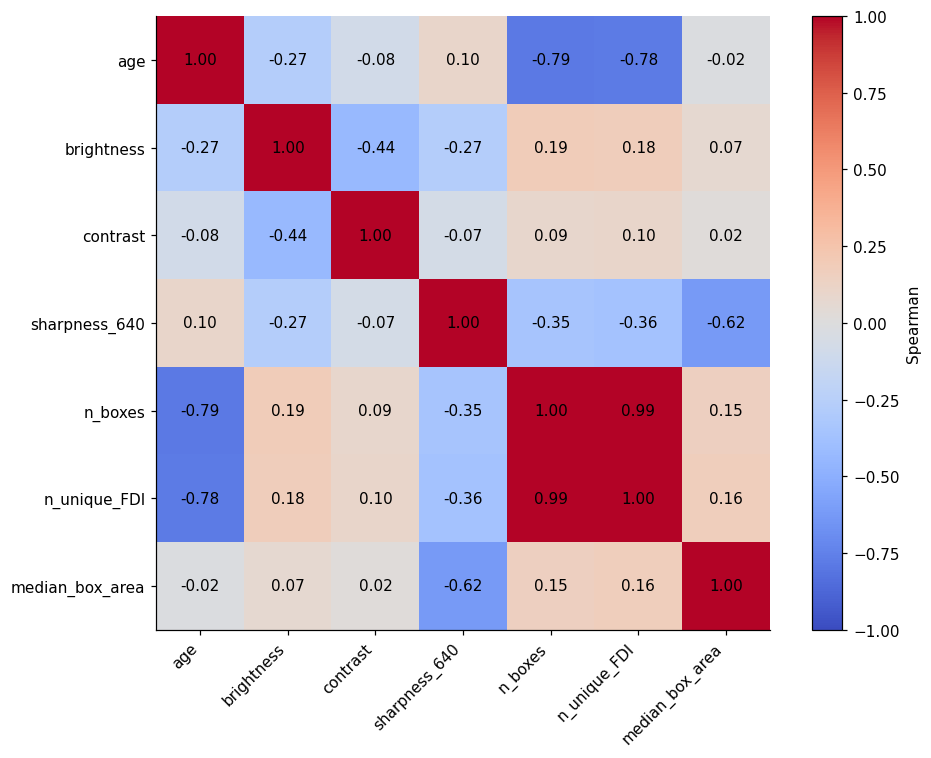

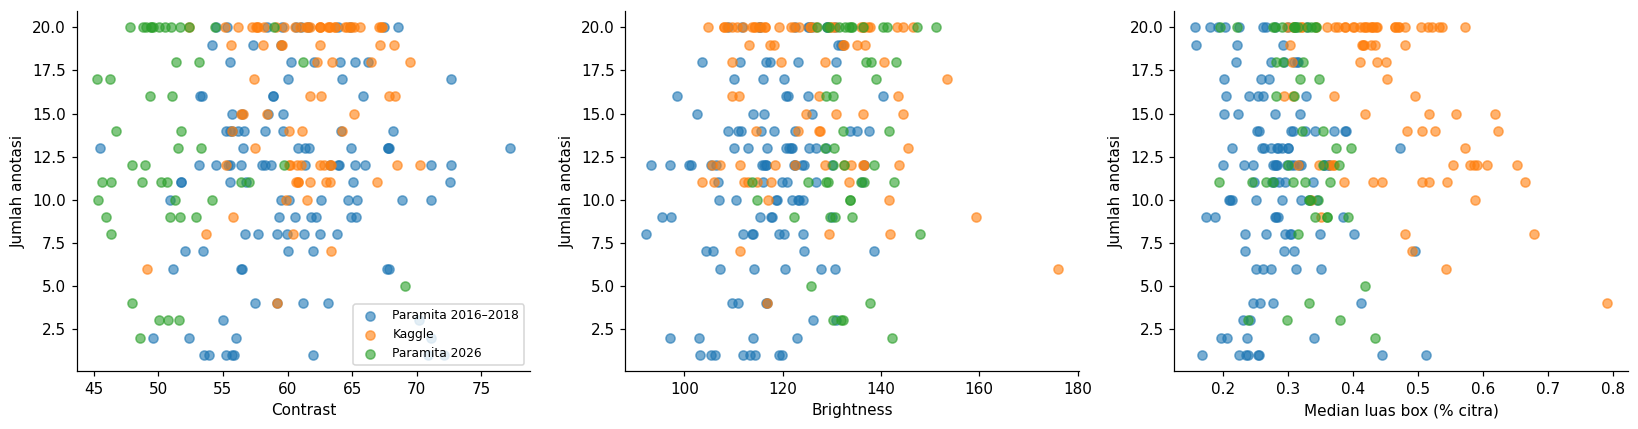


Sumber: Kaggle


,age,brightness,contrast,sharpness_640,n_boxes,n_unique_FDI,median_box_area
age,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brightness,NaN,1.00,-0.52,-0.29,-0.07,-0.08,-0.24
contrast,NaN,-0.52,1.00,0.25,0.12,0.14,-0.16
sharpness_640,NaN,-0.29,0.25,1.00,-0.27,-0.29,-0.03
n_boxes,NaN,-0.07,0.12,-0.27,1.00,0.98,-0.33
n_unique_FDI,NaN,-0.08,0.14,-0.29,0.98,1.00,-0.30
median_box_area,NaN,-0.24,-0.16,-0.03,-0.33,-0.30,1.00



Sumber: Paramita 2016–2018


,age,brightness,contrast,sharpness_640,n_boxes,n_unique_FDI,median_box_area
age,1.00,-0.27,-0.08,0.10,-0.79,-0.78,-0.02
brightness,-0.27,1.00,-0.17,-0.01,0.25,0.23,-0.14
contrast,-0.08,-0.17,1.00,-0.13,0.07,0.08,-0.18
sharpness_640,0.10,-0.01,-0.13,1.00,-0.05,-0.06,0.05
n_boxes,-0.79,0.25,0.07,-0.05,1.00,0.99,-0.04
n_unique_FDI,-0.78,0.23,0.08,-0.06,0.99,1.00,-0.04
median_box_area,-0.02,-0.14,-0.18,0.05,-0.04,-0.04,1.00



Sumber: Paramita 2026


,age,brightness,contrast,sharpness_640,n_boxes,n_unique_FDI,median_box_area
age,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brightness,NaN,1.00,-0.26,-0.03,0.20,0.19,0.12
contrast,NaN,-0.26,1.00,0.30,0.07,0.11,-0.05
sharpness_640,NaN,-0.03,0.30,1.00,0.19,0.19,-0.02
n_boxes,NaN,0.20,0.07,0.19,1.00,0.99,-0.34
n_unique_FDI,NaN,0.19,0.11,0.19,0.99,1.00,-0.31
median_box_area,NaN,0.12,-0.05,-0.02,-0.34,-0.31,1.00



Korelasi bukan sebab-akibat. Korelasi mendekati nol tidak membuktikan
tidak ada pengaruh. Perbedaan sumber dan usia dapat memengaruhi pola.



In [13]:
per_image_object = ann.groupby("image_id").agg(
    median_box_area=("relative_area", "median"),
    median_box_aspect=("box_aspect", "median")
)
analysis = df.merge(per_image_object, on="image_id", how="left")

variables = [
    "age", "brightness", "contrast", "sharpness_640",
    "n_boxes", "n_unique_FDI", "median_box_area"
]

corr = analysis[variables].corr(method="spearman", min_periods=5)
available = analysis[variables].notna().astype(int)
pair_n = available.T @ available

display(corr.round(2))
display(pair_n)

fig, ax = plt.subplots(figsize=(9, 7))
plot = ax.imshow(
    np.ma.masked_invalid(corr.to_numpy()),
    cmap="coolwarm", vmin=-1, vmax=1
)
ax.set_xticks(range(len(variables)), variables, rotation=45, ha="right")
ax.set_yticks(range(len(variables)), variables)

for i in range(len(variables)):
    for j in range(len(variables)):
        value = corr.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")

fig.colorbar(plot, ax=ax, label="Spearman")
saveplot("10_korelasi")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for s in sources:
    g = analysis[analysis.source == s]
    axes[0].scatter(g.contrast, g.n_boxes, alpha=.6, label=s)
    axes[1].scatter(g.brightness, g.n_boxes, alpha=.6)
    axes[2].scatter(g.median_box_area * 100, g.n_boxes, alpha=.6)

axes[0].set(xlabel="Contrast", ylabel="Jumlah anotasi")
axes[1].set(xlabel="Brightness", ylabel="Jumlah anotasi")
axes[2].set(xlabel="Median luas box (% citra)", ylabel="Jumlah anotasi")
axes[0].legend(fontsize=8)
saveplot("11_hubungan_variabel")

corr.to_csv(OUT / "13_korelasi.csv")
pair_n.to_csv(OUT / "14_jumlah_sampel_korelasi.csv")

# Korelasi per sumber sebagai pembanding.
for s, g in analysis.groupby("source"):
    print("\nSumber:", s)
    display(g[variables].corr(method="spearman", min_periods=5).round(2))

print("""
Korelasi bukan sebab-akibat. Korelasi mendekati nol tidak membuktikan
tidak ada pengaruh. Perbedaan sumber dan usia dapat memengaruhi pola.
""")

# Cell 8 — Deteksi outlier jika diperlukan

In [14]:
outlier_rows, boundary_rows = [], []

def scan_iqr(data, group_col, metrics, unit):
    for group_name, group in data.groupby(group_col):
        for metric in metrics:
            values = group[metric].dropna()
            if len(values) < 4:
                continue

            q1, q3 = values.quantile([.25, .75])
            iqr = q3 - q1

            if iqr == 0:
                continue

            lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
            flagged = group[
                (group[metric] < lower) | (group[metric] > upper)
            ]

            boundary_rows.append({
                "unit": unit, "group": group_name,
                "metric": metric, "lower": lower, "upper": upper,
                "n": len(values), "n_outlier": len(flagged),
                "percent": len(flagged) / len(values) * 100
            })

            for _, r in flagged.iterrows():
                outlier_rows.append({
                    "unit": unit, "group": group_name,
                    "image_id": r.image_id,
                    "line": r.get("line", np.nan),
                    "metric": metric, "value": r[metric]
                })

scan_iqr(
    df, "source",
    ["brightness", "contrast", "sharpness_640", "n_boxes"],
    "citra"
)
scan_iqr(
    ann, "FDI",
    ["relative_area", "box_aspect"],
    "anotasi"
)

boundaries = pd.DataFrame(boundary_rows)
outliers = pd.DataFrame(outlier_rows)

display(boundaries.round(3))
display(outliers.head(20))

boundaries.to_csv(OUT / "15_batas_outlier.csv", index=False)
outliers.to_csv(OUT / "16_kandidat_outlier.csv", index=False)

print("""
Flag IQR hanya kandidat tinjauan. Variasi jumlah gigi atau bentuk box
dapat merupakan kondisi nyata. Jumlah flag antarvariabel dapat
tumpang tindih pada citra yang sama.
""")

,unit,group,metric,lower,upper,n,n_outlier,percent
0,citra,Kaggle,brightness,81.510,168.795,83,1,1.205
1,citra,Kaggle,contrast,52.351,70.465,83,2,2.410
2,citra,Kaggle,sharpness_640,128.677,201.457,83,4,4.819
3,citra,Kaggle,n_boxes,0.000,32.000,83,0,0.000
4,citra,Paramita 2016–2018,brightness,92.120,143.545,121,0,0.000
5,citra,Paramita 2016–2018,contrast,43.108,77.566,121,0,0.000
6,citra,Paramita 2016–2018,sharpness_640,704.987,3235.168,121,1,0.826
7,citra,Paramita 2016–2018,n_boxes,-2.500,25.500,121,0,0.000
8,citra,Paramita 2026,brightness,117.188,150.075,48,3,6.250
9,citra,Paramita 2026,contrast,43.931,56.669,48,5,10.417


,unit,group,image_id,line,metric,value
0,citra,Kaggle,IMG0199,NaN,brightness,176.119514
1,citra,Kaggle,IMG0190,NaN,contrast,52.340985
2,citra,Kaggle,IMG0199,NaN,contrast,49.148836
3,citra,Kaggle,IMG0128,NaN,sharpness_640,250.598969
4,citra,Kaggle,IMG0181,NaN,sharpness_640,202.679269
5,citra,Kaggle,IMG0183,NaN,sharpness_640,271.312383
6,citra,Kaggle,IMG0199,NaN,sharpness_640,91.674888
7,citra,Paramita 2016–2018,IMG0003,NaN,sharpness_640,3442.062987
8,citra,Paramita 2026,IMG0222,NaN,brightness,113.694940
9,citra,Paramita 2026,IMG0234,NaN,brightness,151.221651



Flag IQR hanya kandidat tinjauan. Variasi jumlah gigi atau bentuk box
dapat merupakan kondisi nyata. Jumlah flag antarvariabel dapat
tumpang tindih pada citra yang sama.



# Cell 9 — Review visual citra, label berulang, dan outlier

In [15]:
def load_gray(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L")).copy()

def overlay(ax, gray, labels, text):
    H, W = gray.shape
    ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
    freq = labels.FDI.value_counts()

    for r in labels.itertuples():
        color = "red" if freq[r.FDI] > 1 else "lime"
        left, top = (r.x-r.w/2)*W, (r.y-r.h/2)*H
        ax.add_patch(Rectangle(
            (left, top), r.w*W, r.h*H,
            fill=False, edgecolor=color, linewidth=1
        ))
        ax.text(
            left, top, f"{r.FDI} #{r.line}",
            fontsize=6, color="white",
            bbox=dict(facecolor="black", alpha=.65, pad=1)
        )
    ax.set_title(text)
    ax.axis("off")

# Contoh per sumber.
for s in sources:
    r = df[df.source == s].sample(1, random_state=SEED).iloc[0]
    fig, ax = plt.subplots(figsize=(13, 6))
    overlay(
        ax, load_gray(r.path),
        ann[ann.image_id == r.image_id],
        f"{r.image_id} | {s} | {r.age_text}"
    )
    saveplot(f"contoh_{r.image_id}")

# Semua citra dengan FDI berulang.
for uid in repeated.image_id.unique():
    r = df[df.image_id == uid].iloc[0]
    fig, ax = plt.subplots(figsize=(13, 6))
    overlay(ax, load_gray(r.path), ann[ann.image_id == uid],
            f"{uid} — review FDI berulang")
    saveplot(f"review_FDI_{uid}")

# Maksimal tiga citra contoh outlier.
if len(outliers):
    for uid in outliers.image_id.drop_duplicates().head(3):
        r = df[df.image_id == uid].iloc[0]
        fig, ax = plt.subplots(figsize=(13, 6))
        overlay(ax, load_gray(r.path), ann[ann.image_id == uid],
                f"{uid} — kandidat outlier")
        saveplot(f"review_outlier_{uid}")

print("Merah: FDI berulang. # menunjukkan baris file label.")

Output hidden; open in https://colab.research.google.com to view.

# Cell 10 — Duplikat dan kelompok yang tidak boleh dipisahkan

In [16]:
exact = df[df.duplicated("pixel_hash", keep=False)]
display(exact[["image_id", "filename", "source"]])
exact.to_csv(OUT / "17_duplikat_piksel.csv", index=False)

similar_rows = []
records = list(df.itertuples())

for i, a in enumerate(records):
    for b in records[i+1:]:
        distance = sum(x != y for x, y in zip(a.dhash, b.dhash))
        if distance <= 5:
            similar_rows.append({
                "image_a": a.image_id, "image_b": b.image_id,
                "distance": distance
            })

similar = pd.DataFrame(
    similar_rows, columns=["image_a", "image_b", "distance"]
)
display(similar)
similar.to_csv(OUT / "18_kandidat_mirip.csv", index=False)

for pair in similar.sort_values("distance").head(5).itertuples():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, uid in zip(axes, [pair.image_a, pair.image_b]):
        r = df[df.image_id == uid].iloc[0]
        ax.imshow(load_gray(r.path), cmap="gray", vmin=0, vmax=255)
        ax.set_title(uid)
        ax.axis("off")
    saveplot(f"mirip_{pair.image_a}_{pair.image_b}")

# Isi setelah konfirmasi, kemudian jalankan ulang Cell 10 dan seterusnya.
SAME_GROUP_PAIRS = []  # contoh: [("IMG0001", "IMG0020")]

parent = list(range(len(df)))

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[b] = a

seen = {}
for i, r in df.reset_index(drop=True).iterrows():
    tokens = [
        ("name", name_key(r.filename)),
        ("pixel", r.pixel_hash)
    ]
    if r.filename in PATIENT_IDS:
        tokens.append(("patient", str(PATIENT_IDS[r.filename])))

    for token in tokens:
        if token in seen:
            union(i, seen[token])
        else:
            seen[token] = i

index_by_id = {uid: i for i, uid in enumerate(df.image_id)}
for a, b in SAME_GROUP_PAIRS:
    union(index_by_id[a], index_by_id[b])

df["group_id"] = [find(i) for i in range(len(df))]

print("Jumlah citra:", len(df))
print("Jumlah kelompok:", df.group_id.nunique())
print("Jumlah file dengan ID pasien terverifikasi:",
      df.filename.isin(PATIENT_IDS).sum())

Output hidden; open in https://colab.research.google.com to view.

# Cell 11 — Split 70/20/10 dan pemeriksaan kebocoran

source,Kaggle,Paramita 2016–2018,Paramita 2026
split,,,
test,9,13,5
train,57,84,34
valid,17,24,9


,jumlah_citra
split,
train,175
valid,50
test,27


### Kandidat gambar mirip lintas split — perlu ditinjau

,image_a,image_b,distance,split_a,split_b
0,IMG0002,IMG0048,5,train,test
1,IMG0018,IMG0119,5,test,train
3,IMG0024,IMG0070,5,valid,train
4,IMG0034,IMG0062,5,valid,test
5,IMG0034,IMG0083,4,valid,train
6,IMG0048,IMG0087,3,test,valid
7,IMG0048,IMG0105,5,test,train
8,IMG0056,IMG0080,4,train,test
9,IMG0064,IMG0087,5,train,valid
11,IMG0080,IMG0104,4,test,train


split,train,valid,test
FDI,,,
51,60,24,7
52,87,29,11
53,156,47,22
54,145,47,19
55,163,48,26
61,60,22,7
62,87,28,14
63,157,44,20
64,147,41,20


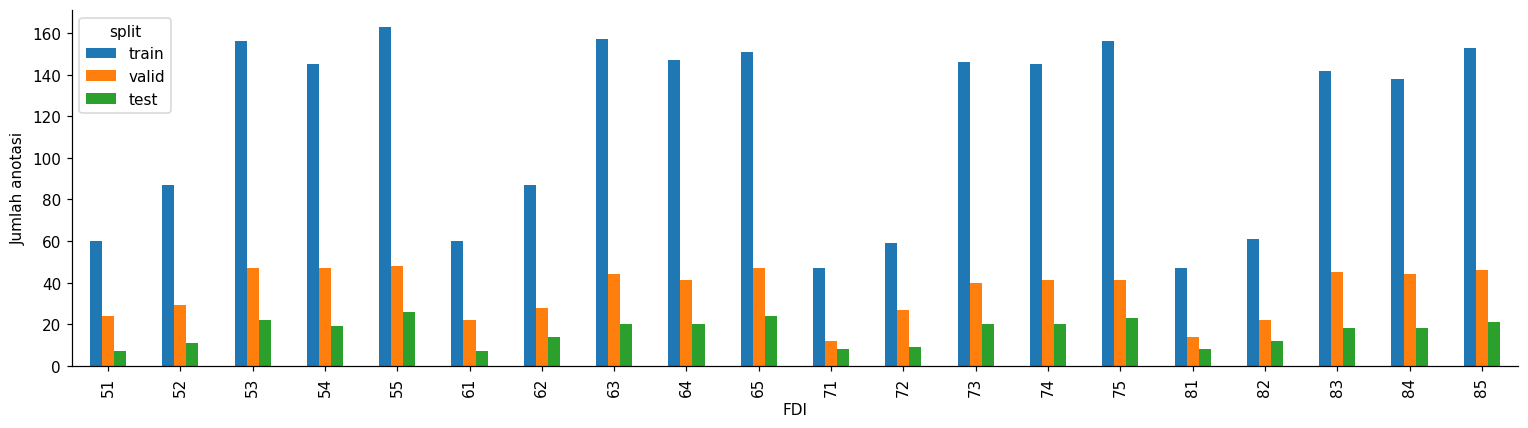

split,test,train,valid
age_text,,,
10 tahun,2,7,3
11 tahun,1,3,1
12 tahun,1,3,1
4 tahun,1,4,1
5 tahun,0,7,3
6 tahun,2,8,4
7 tahun,3,17,3
8 tahun,2,15,5
9 tahun,1,20,2



Pembagian mempertahankan kelompok yang diketahui.
Tanpa ID pasien lengkap, tidak dapat menjamin seluruh pasien antar
split berbeda. Kandidat kemiripan lintas split perlu review.



In [17]:
groups = df.groupby("group_id").agg(
    source=("source", "first"),
    n_images=("image_id", "size")
).reset_index()

n_train = int(.70 * len(groups))
n_valid = int(.20 * len(groups))

try:
    train_groups, remaining = train_test_split(
        groups, train_size=n_train,
        random_state=SEED, stratify=groups.source
    )
    valid_groups, test_groups = train_test_split(
        remaining, train_size=n_valid,
        random_state=SEED, stratify=remaining.source
    )
except ValueError:
    print("Stratifikasi tidak memungkinkan; memakai pembagian acak per kelompok.")
    train_groups, remaining = train_test_split(
        groups, train_size=n_train, random_state=SEED
    )
    valid_groups, test_groups = train_test_split(
        remaining, train_size=n_valid, random_state=SEED
    )

split_map = {
    **dict.fromkeys(train_groups.group_id, "train"),
    **dict.fromkeys(valid_groups.group_id, "valid"),
    **dict.fromkeys(test_groups.group_id, "test")
}
df["split"] = df.group_id.map(split_map)

display(pd.crosstab(df.split, df.source))
display(df.split.value_counts().rename("jumlah_citra"))

# Audit kelompok dan duplikat identik lintas split.
assert df.groupby("group_id").split.nunique().max() == 1
assert df.groupby("pixel_hash").split.nunique().max() == 1

split_lookup = df.set_index("image_id").split
similar["split_a"] = similar.image_a.map(split_lookup)
similar["split_b"] = similar.image_b.map(split_lookup)
cross_split_similar = similar[similar.split_a != similar.split_b]

title("Kandidat gambar mirip lintas split — perlu ditinjau")
display(cross_split_similar)
cross_split_similar.to_csv(
    OUT / "19_kandidat_kemiripan_lintas_split.csv", index=False
)

split_ann = ann.merge(df[["image_id", "split"]], on="image_id")
class_split = pd.crosstab(
    split_ann.FDI, split_ann.split
).reindex(index=FDI, columns=["train", "valid", "test"], fill_value=0)

display(class_split)
class_split.plot.bar(figsize=(14, 4))
plt.ylabel("Jumlah anotasi")
saveplot("12_FDI_per_split")

display(pd.crosstab(df.age_text, df.split))
df.to_csv(OUT / "20_manifest_split.csv", index=False)
class_split.to_csv(OUT / "21_FDI_per_split.csv")

print("""
Pembagian mempertahankan kelompok yang diketahui.
Tanpa ID pasien lengkap, tidak dapat menjamin seluruh pasien antar
split berbeda. Kandidat kemiripan lintas split perlu review.
""")

# Cell 12A — Siapkan fungsi

In [18]:
def orient_point(x, y, orientation):
    transforms = {
        1: (x, y),
        2: (1-x, y),
        3: (1-x, 1-y),
        4: (x, 1-y),
        5: (y, x),
        6: (1-y, x),
        7: (1-y, 1-x),
        8: (y, 1-x)
    }
    return transforms[orientation]


# Tetap kompatibel dengan Cell 14 untuk ekspor.
def preprocess(row):
    labels = ann[ann.image_id == row.image_id].copy()

    with Image.open(row.path) as im:
        original = np.asarray(im.convert("L")).copy()
        orientation = int(im.getexif().get(274, 1))

        if orientation not in range(1, 9):
            raise ValueError("EXIF orientation tidak dikenali")

        oriented = np.asarray(
            ImageOps.exif_transpose(im).convert("L")
        ).copy()

    # Sesuaikan bounding box bila orientasi berubah.
    for idx, b in labels.iterrows():
        corners = [
            orient_point(x, y, orientation)
            for x in [b.x-b.w/2, b.x+b.w/2]
            for y in [b.y-b.h/2, b.y+b.h/2]
        ]

        xs, ys = zip(*corners)
        labels.loc[idx, ["x", "y", "w", "h"]] = [
            (min(xs)+max(xs))/2,
            (min(ys)+max(ys))/2,
            max(xs)-min(xs),
            max(ys)-min(ys)
        ]

    equalized = cv2.equalizeHist(oriented)
    return original, oriented, equalized, labels


def brightness_variant(img, factor):
    return np.clip(
        np.round(img.astype(np.float32) * factor),
        0, 255
    ).astype(np.uint8)


def intensity_metrics(img):
    return {
        "brightness": float(img.mean()),
        "contrast": float(img.std()),
        "dark_pct": float((img <= 5).mean() * 100),
        "bright_pct": float((img >= 250).mean() * 100)
    }


train_df = df[df.split == "train"].copy()

# Satu contoh train dari setiap sumber.
examples = train_df.groupby("source").sample(
    n=1, random_state=SEED
)

display(examples[["image_id", "source", "age_text", "split"]])

print("Seluruh contoh berasal dari train.")
print("EXIF orientation train:",
      train_df.orientation.value_counts().to_dict())

,image_id,source,age_text,split
121,IMG0122,Kaggle,Tidak ada keterangan umur,train
103,IMG0104,Paramita 2016–2018,7 tahun,train
239,IMG0240,Paramita 2026,Tidak ada keterangan umur,train


Seluruh contoh berasal dari train.
EXIF orientation train: {1: 175}


# Cell 12B — Empat perbandingan before–after terpisah

In [19]:
def compare_images(uid, comparison_name, versions, output_name):
    """
    versions = [(nama_versi, array_grayscale), ...]
    """
    fig, axes = plt.subplots(
        2, len(versions),
        figsize=(6 * len(versions), 8),
        squeeze=False
    )

    stats = []

    for j, (label, img) in enumerate(versions):
        axes[0, j].imshow(
            img, cmap="gray", vmin=0, vmax=255
        )
        axes[0, j].set_title(label)
        axes[0, j].axis("off")

        axes[1, j].hist(
            img.ravel(),
            bins=64,
            range=(0, 256),
            density=True,
            color="#2878B5"
        )
        axes[1, j].set(
            xlim=(0, 255),
            xlabel="Intensitas piksel",
            ylabel="Density"
        )

        stats.append({
            "image_id": uid,
            "perbandingan": comparison_name,
            "versi": label,
            **intensity_metrics(img)
        })

    fig.suptitle(f"{uid} — {comparison_name}", fontsize=14)
    saveplot(output_name)

    table = pd.DataFrame(stats)
    display(table.round(3))
    return table


comparison_tables = []

for row in examples.itertuples():
    original, oriented, equalized, labels = preprocess(row)

    title(f"Contoh {row.image_id} — {row.source}")

    # 1. ORIGINAL vs AUTO-ORIENT SAJA
    comparison_tables.append(compare_images(
        row.image_id,
        "Original vs Auto-Orient",
        [
            ("Original", original),
            ("Auto-Orient saja", oriented)
        ],
        f"BA_1_autoorient_{row.image_id}"
    ))

    # 2. ORIGINAL vs HISTOGRAM EQUALIZATION SAJA
    # Diterapkan langsung pada original untuk mengisolasi efek histogram.
    histogram_only = cv2.equalizeHist(original)

    comparison_tables.append(compare_images(
        row.image_id,
        "Original vs Histogram Equalization",
        [
            ("Original", original),
            ("Histogram Equalization saja", histogram_only)
        ],
        f"BA_2_histogram_{row.image_id}"
    ))

    # 3. ORIGINAL vs BRIGHTNESS SAJA
    comparison_tables.append(compare_images(
        row.image_id,
        "Original vs Brightness",
        [
            ("Original", original),
            ("Brightness −15% saja",
             brightness_variant(original, .85)),
            ("Brightness +15% saja",
             brightness_variant(original, 1.15))
        ],
        f"BA_3_brightness_{row.image_id}"
    ))

    # 4. ORIGINAL vs GABUNGAN SEMUA
    # equalized sudah berasal dari Auto-Orient → Histogram Equalization.
    comparison_tables.append(compare_images(
        row.image_id,
        "Original vs gabungan seluruh proses",
        [
            ("Original", original),
            ("Auto-Orient → Histogram → −15%",
             brightness_variant(equalized, .85)),
            ("Auto-Orient → Histogram → +15%",
             brightness_variant(equalized, 1.15))
        ],
        f"BA_4_gabungan_{row.image_id}"
    ))

all_comparisons = pd.concat(comparison_tables, ignore_index=True)
all_comparisons.to_csv(
    OUT / "22_perbandingan_terpisah_before_after.csv",
    index=False
)

print("""
Catatan:
- Auto-Orient dapat tampak sama jika EXIF sudah normal.
- Brightness −15% dan +15% adalah dua alternatif.
  Keduanya tidak diterapkan berurutan pada satu gambar.
- Sel ini hanya membandingkan hasil; belum mengekspor dataset augmentasi.
""")

Output hidden; open in https://colab.research.google.com to view.

# Cell 13 — Augmentasi train menjadi 3 versi

### Tiga versi train setelah preprocessing dan augmentasi

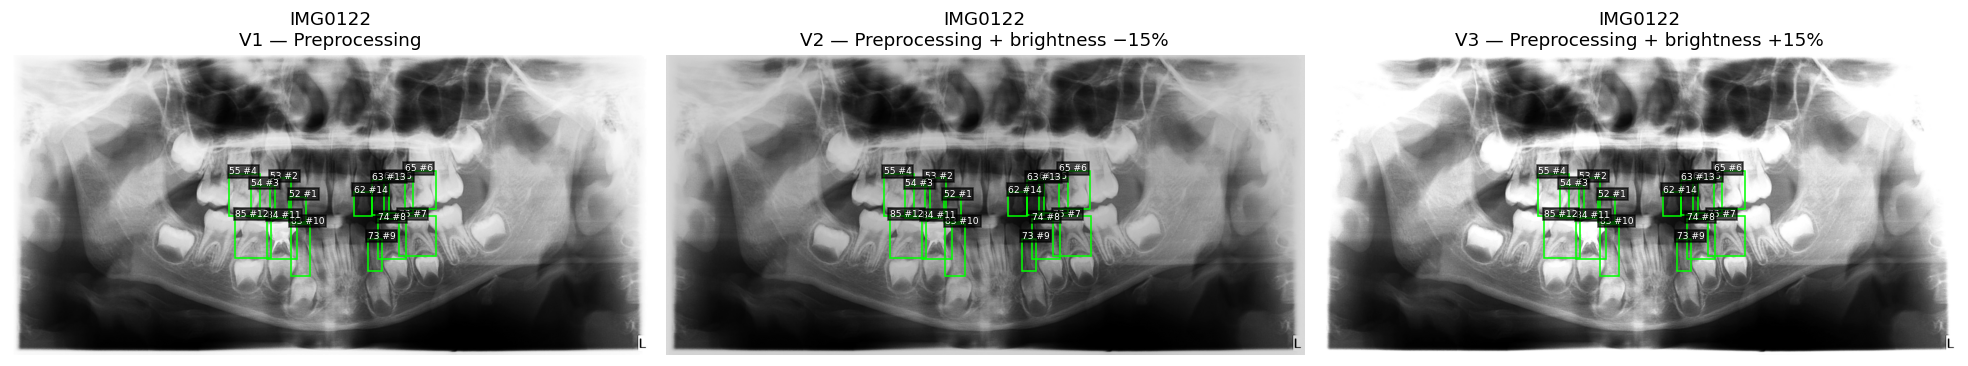

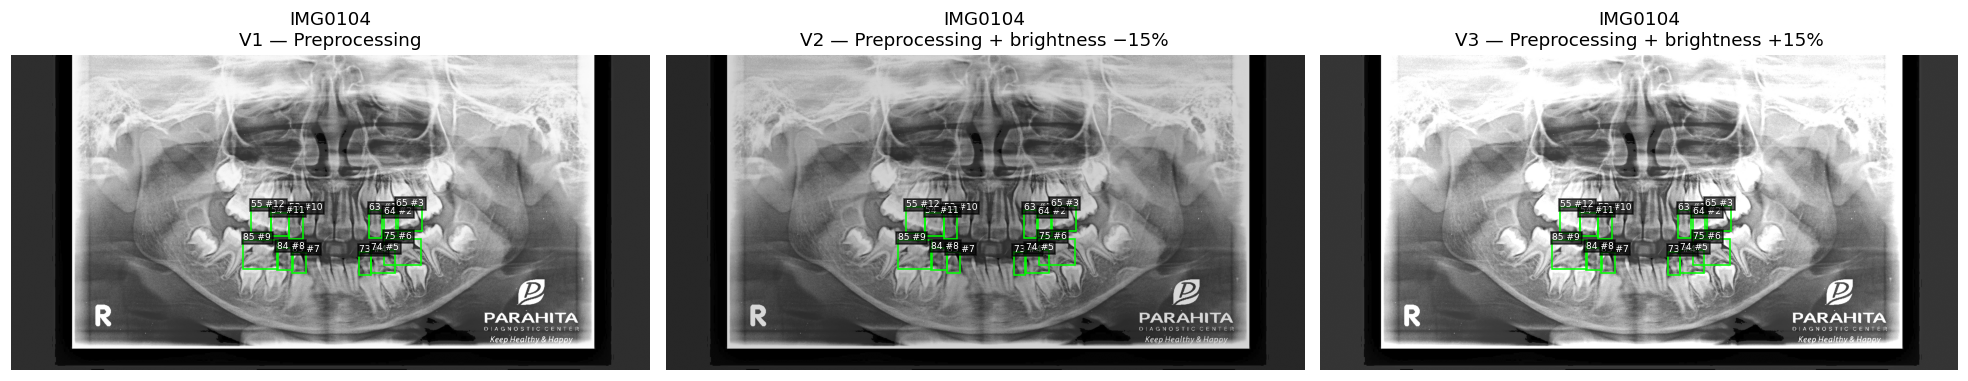

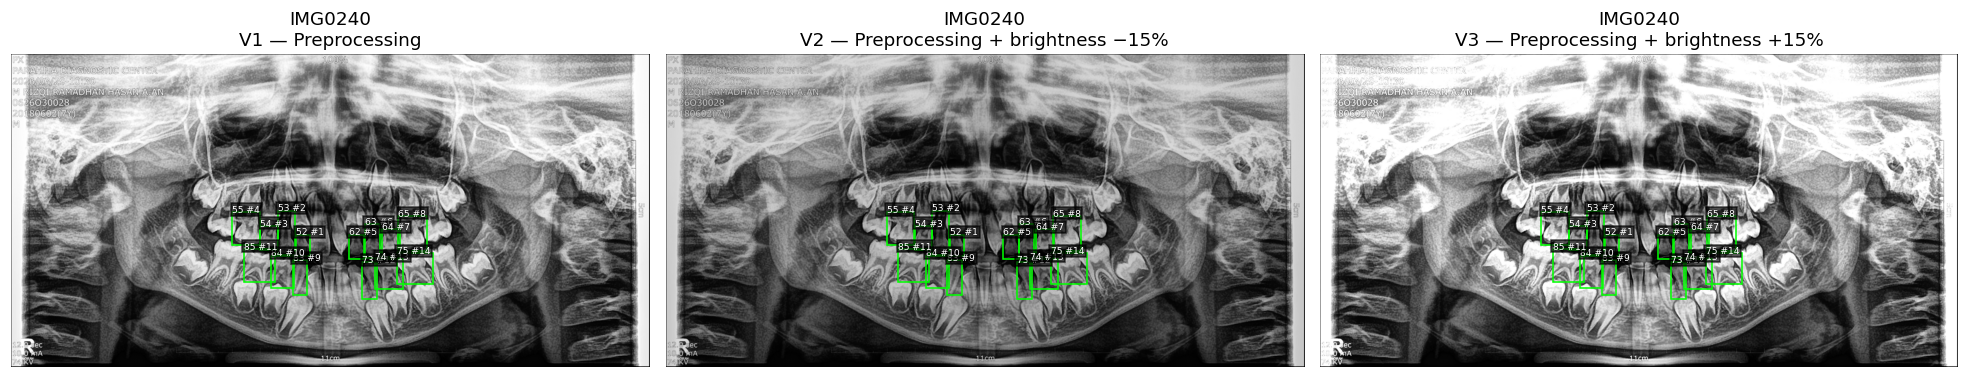

,brightness,contrast,dark_pct,bright_pct
version,,,,
V1: preprocessing saja,126.309,74.734,3.392,2.201
V2: preprocessing + brightness −15%,107.378,63.527,3.796,0.000
V3: preprocessing + brightness +15%,142.739,82.220,2.891,15.104


,Split,Citra sumber,Versi per citra,Jumlah file hasil,Pengolahan
0,train,175,3,525,"Auto-Orient + Histogram; versi dasar, −15%, +15%"
1,valid,50,1,50,Auto-Orient + Histogram; tanpa augmentasi
2,test,27,1,27,Auto-Orient + Histogram; tanpa augmentasi


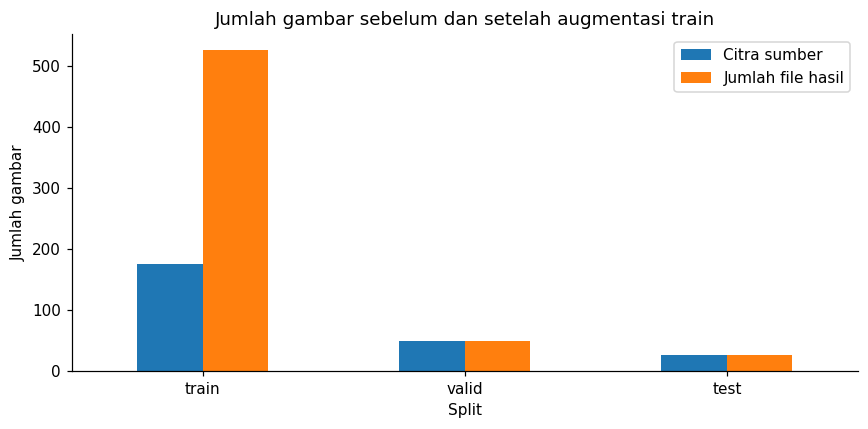


Data validation dan test tidak diberi augmentasi brightness.
Augmentasi train tidak menambah jumlah pasien atau sumber independen.
Lanjutkan Cell 14 untuk ekspor setelah hasil ditinjau.



In [20]:
title("Tiga versi train setelah preprocessing dan augmentasi")

augmentation_rows = []

for row in train_df.itertuples():
    _, _, base, labels = preprocess(row)

    for version, factor in [
        ("V1: preprocessing saja", 1.0),
        ("V2: preprocessing + brightness −15%", .85),
        ("V3: preprocessing + brightness +15%", 1.15)
    ]:
        img = brightness_variant(base, factor)

        augmentation_rows.append({
            "image_id": row.image_id,
            "version": version,
            "factor": factor,
            **intensity_metrics(img)
        })


# Tampilkan contoh dengan label untuk memastikan kotak tetap sesuai.
for row in examples.itertuples():
    _, _, base, labels = preprocess(row)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (label, factor) in zip(axes, [
        ("V1 — Preprocessing", 1.0),
        ("V2 — Preprocessing + brightness −15%", .85),
        ("V3 — Preprocessing + brightness +15%", 1.15)
    ]):
        overlay(
            ax,
            brightness_variant(base, factor),
            labels,
            f"{row.image_id}\n{label}"
        )

    saveplot(f"train_3_versi_{row.image_id}")


augmentation = pd.DataFrame(augmentation_rows)

display(
    augmentation.groupby("version")[
        ["brightness", "contrast", "dark_pct", "bright_pct"]
    ].median().round(3)
)

augmentation.to_csv(
    OUT / "23_statistik_augmentasi_train.csv",
    index=False
)


# Jumlah sumber vs jumlah file setelah pengolahan.
split_counts = df.split.value_counts()

plan = pd.DataFrame([
    {
        "Split": split,
        "Citra sumber": int(split_counts.get(split, 0)),
        "Versi per citra": 3 if split == "train" else 1,
        "Jumlah file hasil": (
            int(split_counts.get(split, 0))
            * (3 if split == "train" else 1)
        ),
        "Pengolahan": (
            "Auto-Orient + Histogram; versi dasar, −15%, +15%"
            if split == "train"
            else "Auto-Orient + Histogram; tanpa augmentasi"
        )
    }
    for split in ["train", "valid", "test"]
])

display(plan)
plan.to_csv(OUT / "24_rencana_jumlah_setelah_augmentasi.csv", index=False)

plan.set_index("Split")[
    ["Citra sumber", "Jumlah file hasil"]
].plot.bar(figsize=(8, 4), rot=0)

plt.ylabel("Jumlah gambar")
plt.title("Jumlah gambar sebelum dan setelah augmentasi train")
saveplot("jumlah_sebelum_setelah_augmentasi")

print("""
Data validation dan test tidak diberi augmentasi brightness.
Augmentasi train tidak menambah jumlah pasien atau sumber independen.
Lanjutkan Cell 14 untuk ekspor setelah hasil ditinjau.
""")

# Cell 14 — Ekspor dataset setelah hasil ditinjau

In [21]:
# EXPORT_DATASET = True

if EXPORT_DATASET:
    DATAOUT = OUT / "dataset_processed"

    for split in ["train", "valid", "test"]:
        (DATAOUT / split / "images").mkdir(parents=True, exist_ok=True)
        (DATAOUT / split / "labels").mkdir(exist_ok=True)

    export_rows = []

    for r in df.itertuples():
        _, _, base, labels = preprocess(r)

        variants = [(1.0, "base")]
        if r.split == "train":
            variants += [(.85, "dark"), (1.15, "bright")]

        label_text = "\n".join(
            f"{int(b.class_id)} {b.x:.8f} {b.y:.8f} {b.w:.8f} {b.h:.8f}"
            for b in labels.itertuples()
        )

        for factor, suffix in variants:
            stem = f"{r.image_id}_{suffix}"
            img = brightness_variant(base, factor)

            Image.fromarray(img).convert("RGB").save(
                DATAOUT / r.split / "images" / f"{stem}.png"
            )
            (DATAOUT / r.split / "labels" / f"{stem}.txt").write_text(
                label_text
            )

            export_rows.append({
                "output": stem,
                "image_id": r.image_id,
                "original_filename": r.filename,
                "group_id": r.group_id,
                "split": r.split,
                "brightness_factor": factor
            })

    exported = pd.DataFrame(export_rows)
    exported.to_csv(DATAOUT / "manifest.csv", index=False)

    with open(DATAOUT / "data.yaml", "w") as f:
        yaml.safe_dump({
            "path": str(DATAOUT),
            "train": "train/images",
            "val": "valid/images",
            "test": "test/images",
            "nc": len(FDI),
            "names": FDI
        }, f, sort_keys=False)

    # Pemeriksaan jumlah dan kelompok setelah ekspor.
    assert exported.groupby("group_id").split.nunique().max() == 1

    for split in ["train", "valid", "test"]:
        image_count = len(list((DATAOUT/split/"images").glob("*.png")))
        label_count = len(list((DATAOUT/split/"labels").glob("*.txt")))
        assert image_count == label_count

    display(exported.groupby("split").agg(
        jumlah_file=("output", "size"),
        citra_sumber=("image_id", "nunique")
    ))
    print("Dataset hasil:", DATAOUT)
    print("Jika dipindah, sesuaikan field path pada data.yaml.")

else:
    print("Ekspor belum dijalankan. Seluruh EDA dan before–after tetap tersedia.")

Ekspor belum dijalankan. Seluruh EDA dan before–after tetap tersedia.


# Cell 15 — Ringkasan, insight, dan unduhan

In [22]:
summary = pd.DataFrame({
    "Aspek": [
        "Tujuan",
        "Jumlah citra berlabel",
        "Jumlah bounding box",
        "Jumlah kelas",
        "Usia tanpa keterangan",
        "Citra dengan FDI berulang",
        "Pembagian data",
        "Preprocessing",
        "Augmentasi"
    ],
    "Hasil": [
        "Deteksi dan enumerasi gigi susu berdasarkan FDI; cakupan penelitian 1–12 tahun",
        len(df),
        len(ann),
        len(FDI),
        int(df.age.isna().sum()),
        int(repeated.image_id.nunique()),
        str(df.split.value_counts().to_dict()),
        "Auto-Orient + histogram equalization",
        "Train saja: versi dasar + brightness -15% + brightness +15%"
    ]
})
display(summary)
summary.to_csv(OUT / "24_ringkasan.csv", index=False)

insights = pd.DataFrame([
    [
        "Komposisi sumber dan usia",
        "Tabel seleksi, sumber, dan keterangan umur",
        "Jelaskan cakupan; jangan mengasumsikan usia yang tidak tersedia."
    ],
    [
        "Distribusi FDI",
        "Frekuensi tiap FDI dan jumlah citra yang memuatnya",
        "Deskripsikan kondisi dataset; evaluasi model nantinya per kelas."
    ],
    [
        "Jumlah label per citra",
        "Histogram, boxplot, tabel per citra",
        "Bedakan jumlah box dengan FDI unik."
    ],
    [
        "Ukuran, bentuk, posisi",
        "Luas relatif, rasio box, heatmap pusat",
        "Jelaskan variasi objek dan kebutuhan resolusi sebagai kandidat eksperimen."
    ],
    [
        "Hubungan variabel",
        "Spearman dan scatter plot",
        "Hindari kesimpulan sebab-akibat."
    ],
    [
        "Outlier dan anotasi",
        "IQR serta overlay",
        "Isi hasil review; jangan otomatis menghapus."
    ],
    [
        "Kebocoran split",
        "Kelompok, hash, kandidat kemiripan",
        "Laporkan keterbatasan jika ID pasien belum lengkap."
    ],
    [
        "Before–after",
        "Citra, histogram, tabel, boxplot",
        "Jelaskan perubahan intensitas dan kualitas visual; belum klaim kenaikan akurasi."
    ]
], columns=["Aspek", "Bukti", "Interpretasi yang diperlukan"])

display(insights)
insights.to_csv(OUT / "25_kerangka_insight.csv", index=False)

# ZIP tabel dan grafik saja, tidak menyertakan dataset ekspor.
archive = OUT / f"EDA_FDI_{RUN_ID}.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        if p.is_file() and p != archive:
            z.write(p, p.name)

print("Semua hasil tersimpan:", OUT)
print("ZIP tabel dan grafik tersimpan:", archive)

,Aspek,Hasil
0,Tujuan,Deteksi dan enumerasi gigi susu berdasarkan FD...
1,Jumlah citra berlabel,252
2,Jumlah bounding box,3343
3,Jumlah kelas,20
4,Usia tanpa keterangan,132
5,Citra dengan FDI berulang,25
6,Pembagian data,"{'train': 175, 'valid': 50, 'test': 27}"
7,Preprocessing,Auto-Orient + histogram equalization
8,Augmentasi,Train saja: versi dasar + brightness -15% + br...


,Aspek,Bukti,Interpretasi yang diperlukan
0,Komposisi sumber dan usia,"Tabel seleksi, sumber, dan keterangan umur",Jelaskan cakupan; jangan mengasumsikan usia ya...
1,Distribusi FDI,Frekuensi tiap FDI dan jumlah citra yang memua...,Deskripsikan kondisi dataset; evaluasi model n...
2,Jumlah label per citra,"Histogram, boxplot, tabel per citra",Bedakan jumlah box dengan FDI unik.
3,"Ukuran, bentuk, posisi","Luas relatif, rasio box, heatmap pusat",Jelaskan variasi objek dan kebutuhan resolusi ...
4,Hubungan variabel,Spearman dan scatter plot,Hindari kesimpulan sebab-akibat.
5,Outlier dan anotasi,IQR serta overlay,Isi hasil review; jangan otomatis menghapus.
6,Kebocoran split,"Kelompok, hash, kandidat kemiripan",Laporkan keterbatasan jika ID pasien belum len...
7,Before–after,"Citra, histogram, tabel, boxplot",Jelaskan perubahan intensitas dan kualitas vis...


Semua hasil tersimpan: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/EDA_FDI_lengkap_20261031_140236
ZIP tabel dan grafik tersimpan: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/EDA_FDI_lengkap_20261031_140236/EDA_FDI_20261031_140236.zip


Cakupan analisis: Simulasi EDA — belum dibatasi ke train
Jumlah citra sumber berhasil: 252


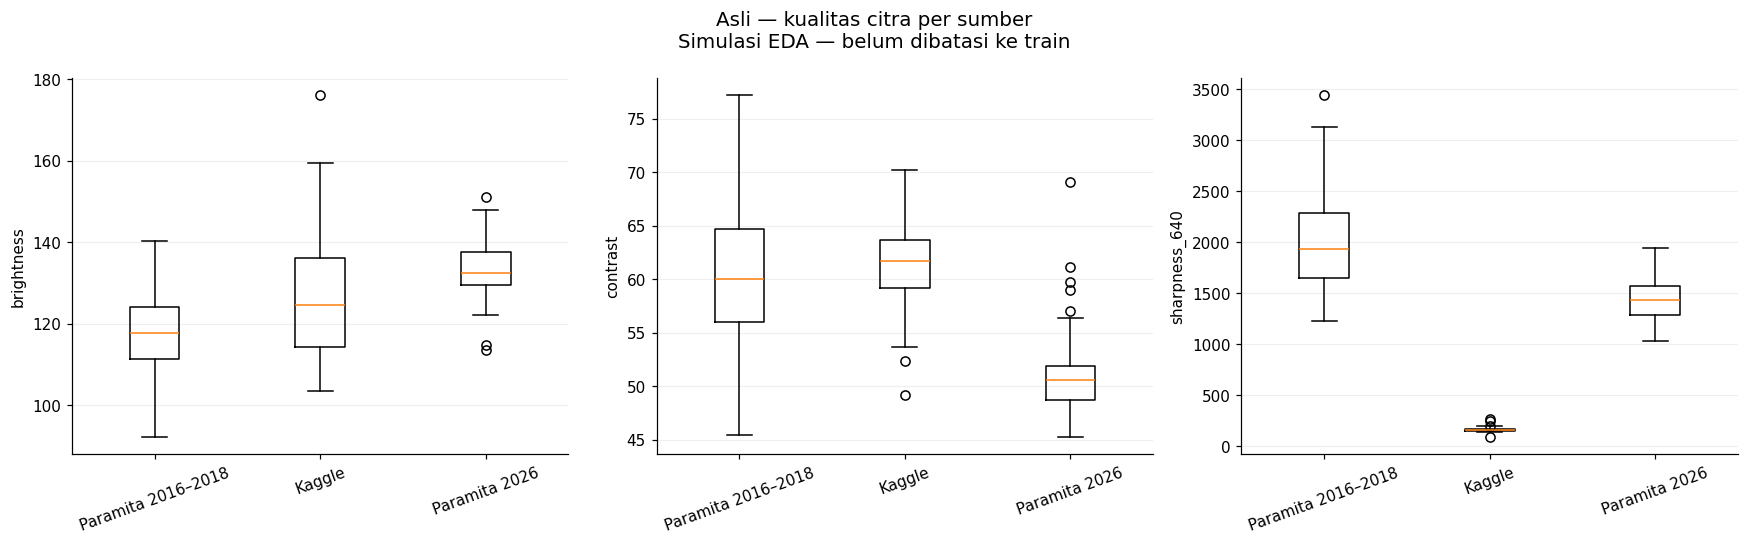

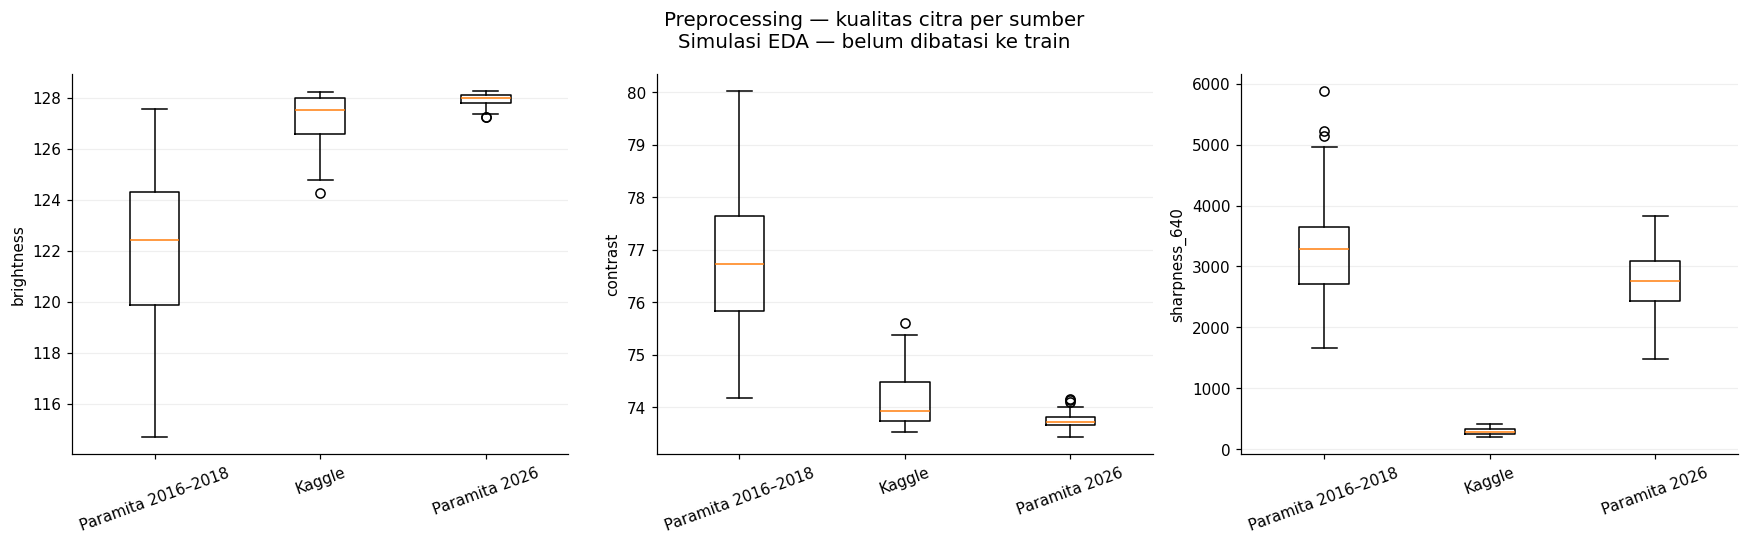

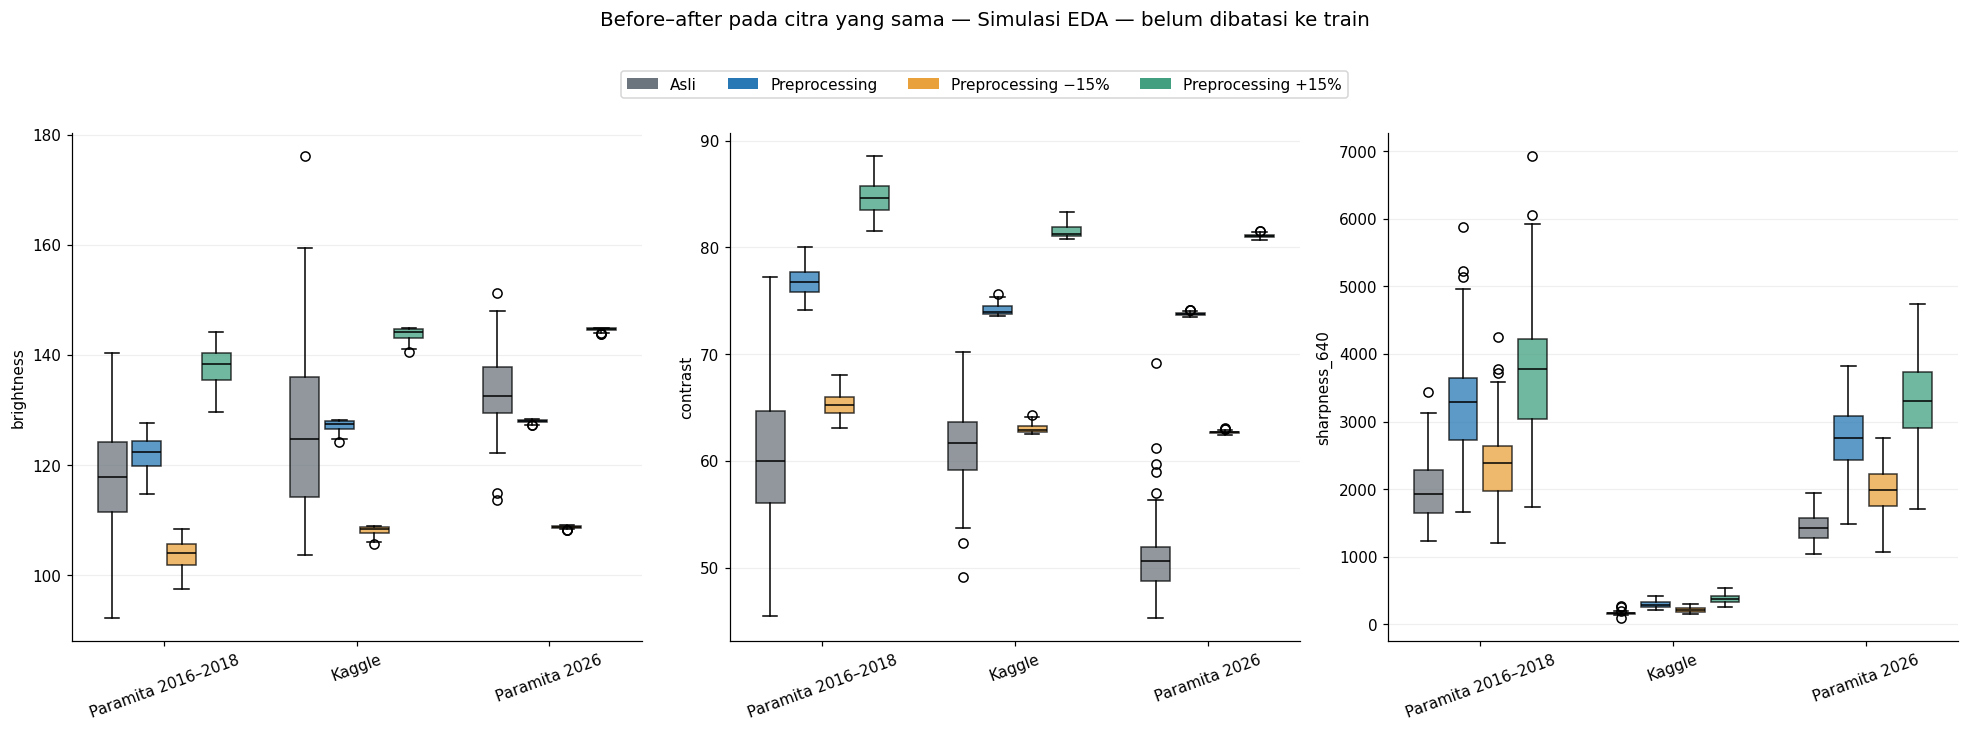

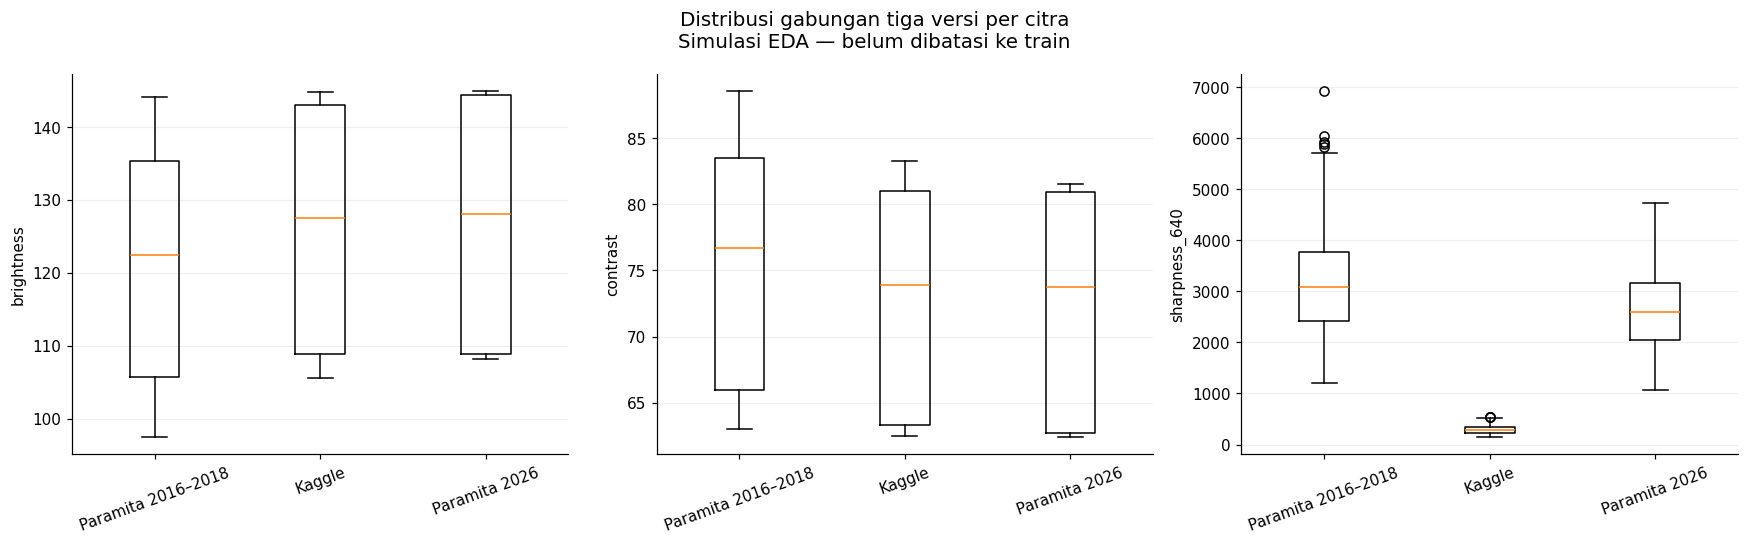


Median kualitas menurut sumber dan tahap:


brightness  contrast  sharpness_640  \
source             stage                                                     
Kaggle             Asli                   124.710    61.696        165.404   
                   Preprocessing          127.519    73.933        288.586   
                   Preprocessing +15%     144.093    81.263        368.260   
                   Preprocessing −15%     108.394    62.846        209.937   
Paramita 2016–2018 Asli                   117.779    59.997       1935.096   
                   Preprocessing          122.437    76.733       3294.456   
                   Preprocessing +15%     138.350    84.595       3778.506   
                   Preprocessing −15%     104.073    65.216       2382.275   
Paramita 2026      Asli                   132.588    50.584       1431.454   
                   Preprocessing          128.003    73.729       2757.742   
                   Preprocessing +15%     144.662    81.060       3304.139   
                   Preprocessing −15%     108.804    62.671       1993.162   

                                       dark_pct  bright_pct  
source             stage                                     
Kaggle             Asli                   1.846       1.919  
                   Preprocessing          2.481       2.214  
                   Preprocessing +15%     2.005      15.142  
                   Preprocessing −15%     2.895       0.000  
Paramita 2016–2018 Asli                   7.159       0.484  
                   Preprocessing          6.548       2.133  
                   Preprocessing +15%     6.075      14.712  
                   Preprocessing −15%     6.744       0.000  
Paramita 2026      Asli                   0.633       0.276  
                   Preprocessing          2.295       2.252  
                   Preprocessing +15%     1.879      15.314  
                   Preprocessing −15%     2.642       0.000


Median perubahan setelah histogram equalization:
Nilai positif berarti meningkat dibanding citra asli.


,delta_brightness,delta_contrast,delta_sharpness_640
source,,,
Kaggle,2.885,12.783,123.371
Paramita 2016–2018,4.240,17.144,1242.607
Paramita 2026,-4.980,23.240,1288.254



Interpretasi:
1. Histogram equalization tidak menjamin contrast semua sumber
   menjadi sama atau selalu meningkat.
2. Kenaikan sharpness_640 dapat berasal dari kontras/noise;
   periksa detail gigi pada before–after visual.
3. Brightness ±15% menambah variasi, bukan otomatis menyamakan sumber.
4. Tiga versi merupakan citra turunan dari sumber yang sama.
5. Augmentasi dataset training hanya diterapkan pada train.



In [23]:
# ============================================================
# BEFORE–AFTER KUALITAS CITRA PER SUMBER
# Jalankan setelah cell pembentukan dataframe "meta".
# ============================================================

from matplotlib.patches import Patch

if "meta" not in globals() or meta.empty:
    raise ValueError("Jalankan cell metadata terlebih dahulu.")

required = {"image_id", "source", "path", "readable"}
missing = required - set(meta.columns)
if missing:
    raise ValueError(f"Kolom metadata belum lengkap: {missing}")

# Gunakan train saja bila pembagian sudah tercatat pada meta.
if "split" in meta.columns:
    selected = meta[
        meta.readable & (meta["split"] == "train")
    ].copy()
    scope = "Train"
else:
    selected = meta[meta.readable].copy()
    scope = "Simulasi EDA — belum dibatasi ke train"

if selected.empty:
    raise ValueError("Tidak ada citra yang dapat dianalisis.")

source_order = [
    s for s in
    ["Paramita 2016–2018", "Kaggle", "Paramita 2026"]
    if s in selected.source.unique()
]

metrics = ["brightness", "contrast", "sharpness_640"]

def ukur_kualitas(gray):
    h, w = gray.shape

    # Sama seperti pengukuran pada cell metadata Anda.
    thumbnail = cv2.resize(
        gray, (640, max(3, round(h * 640 / w)))
    )

    return {
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
        "sharpness_640": float(
            cv2.Laplacian(thumbnail, cv2.CV_64F).var()
        ),
        "dark_pct": float((gray <= 5).mean() * 100),
        "bright_pct": float((gray >= 250).mean() * 100)
    }

def ubah_brightness(gray, factor):
    return np.clip(
        np.round(gray.astype(np.float32) * factor),
        0, 255
    ).astype(np.uint8)


# ------------------------------------------------------------
# 1. PROSES CITRA YANG SAMA PADA SETIAP TAHAP
# ------------------------------------------------------------

results = []
failed = []

for row in selected.itertuples():
    try:
        with Image.open(row.path) as im:
            # Metadata sebelumnya juga memakai exif_transpose.
            # Karena itu baseline mengikuti orientasi tampil yang sama.
            original = np.asarray(
                ImageOps.exif_transpose(im).convert("L")
            ).copy()

        equalized = cv2.equalizeHist(original)

        versions = [
            ("Asli", original),
            ("Preprocessing", equalized),
            ("Preprocessing −15%",
             ubah_brightness(equalized, 0.85)),
            ("Preprocessing +15%",
             ubah_brightness(equalized, 1.15))
        ]

        for stage, gray in versions:
            results.append({
                "image_id": row.image_id,
                "source": row.source,
                "stage": stage,
                **ukur_kualitas(gray)
            })

    except Exception as e:
        failed.append({
            "image_id": row.image_id,
            "path": row.path,
            "error": str(e)
        })

processed_metrics = pd.DataFrame(results)

if processed_metrics.empty:
    raise ValueError("Tidak ada citra yang berhasil diproses.")

if failed:
    print("Citra yang gagal diproses:")
    display(pd.DataFrame(failed))

processed_metrics.to_csv(
    HASIL / "07_kualitas_before_after.csv",
    index=False
)

print("Cakupan analisis:", scope)
print(
    "Jumlah citra sumber berhasil:",
    processed_metrics.image_id.nunique()
)


# ------------------------------------------------------------
# 2. GRAFIK ASLI DAN SETELAH PREPROCESSING
# Bentuknya seperti grafik Anda: tiga metrik per sumber.
# ------------------------------------------------------------

for stage in ["Asli", "Preprocessing"]:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, metric in zip(axes, metrics):
        values = [
            processed_metrics.loc[
                (processed_metrics.source == source)
                & (processed_metrics.stage == stage),
                metric
            ].dropna()
            for source in source_order
        ]

        ax.boxplot(values)
        ax.set_xticks(
            range(1, len(source_order) + 1),
            source_order,
            rotation=20
        )
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.2)

    fig.suptitle(
        f"{stage} — kualitas citra per sumber\n{scope}",
        fontsize=13
    )

    simpan_grafik(
        "07_kualitas_asli"
        if stage == "Asli"
        else "08_kualitas_setelah_preprocessing"
    )


# ------------------------------------------------------------
# 3. GRAFIK PERBANDINGAN BERDAMPINGAN
# Setiap sumber: Asli vs Preprocessing vs −15% vs +15%.
# ------------------------------------------------------------

stages = [
    "Asli",
    "Preprocessing",
    "Preprocessing −15%",
    "Preprocessing +15%"
]
colors = ["#6C757D", "#2878B5", "#E9A23B", "#42A080"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

offsets = [-0.27, -0.09, 0.09, 0.27]

for ax, metric in zip(axes, metrics):
    for stage, color, offset in zip(stages, colors, offsets):
        values = [
            processed_metrics.loc[
                (processed_metrics.source == source)
                & (processed_metrics.stage == stage),
                metric
            ].dropna()
            for source in source_order
        ]

        positions = (
            np.arange(1, len(source_order) + 1) + offset
        )

        bp = ax.boxplot(
            values,
            positions=positions,
            widths=0.15,
            patch_artist=True,
            manage_ticks=False,
            medianprops={"color": "black"}
        )

        for box in bp["boxes"]:
            box.set_facecolor(color)
            box.set_alpha(0.75)

    ax.set_xticks(
        range(1, len(source_order) + 1),
        source_order,
        rotation=20
    )
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.2)

fig.legend(
    handles=[
        Patch(facecolor=c, label=s)
        for s, c in zip(stages, colors)
    ],
    loc="upper center",
    ncol=4,
    bbox_to_anchor=(0.5, 1.02)
)

fig.suptitle(
    f"Before–after pada citra yang sama — {scope}",
    y=1.10,
    fontsize=13
)

simpan_grafik("09_perbandingan_kualitas_semua_tahap")


# ------------------------------------------------------------
# 4. GRAFIK DISTRIBUSI TIGA VERSI GABUNGAN
# Meniru komposisi train setelah augmentasi 3×.
# ------------------------------------------------------------

three_versions = processed_metrics[
    processed_metrics.stage.isin([
        "Preprocessing",
        "Preprocessing −15%",
        "Preprocessing +15%"
    ])
].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, metrics):
    values = [
        three_versions.loc[
            three_versions.source == source, metric
        ].dropna()
        for source in source_order
    ]

    ax.boxplot(values)
    ax.set_xticks(
        range(1, len(source_order) + 1),
        source_order,
        rotation=20
    )
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    f"Distribusi gabungan tiga versi per citra\n{scope}",
    fontsize=13
)
simpan_grafik("10_kualitas_gabungan_tiga_versi")


# ------------------------------------------------------------
# 5. TABEL MEDIAN DAN PERUBAHAN BERPASANGAN
# ------------------------------------------------------------

print("\nMedian kualitas menurut sumber dan tahap:")

median_table = (
    processed_metrics.groupby(["source", "stage"])[
        metrics + ["dark_pct", "bright_pct"]
    ].median()
)

display(median_table.round(3))
median_table.to_csv(
    HASIL / "08_median_kualitas_per_tahap.csv"
)

# Perubahan setiap citra, lalu diringkas per sumber.
before = processed_metrics[
    processed_metrics.stage == "Asli"
].set_index("image_id")

after = processed_metrics[
    processed_metrics.stage == "Preprocessing"
].set_index("image_id")

paired = before[["source"]].copy()

for metric in metrics:
    paired[f"delta_{metric}"] = (
        after[metric] - before[metric]
    )

print("\nMedian perubahan setelah histogram equalization:")
print("Nilai positif berarti meningkat dibanding citra asli.")

display(
    paired.groupby("source")
    .median(numeric_only=True)
    .round(3)
)

paired.to_csv(
    HASIL / "09_perubahan_berpasangan_preprocessing.csv"
)

print("""
Interpretasi:
1. Histogram equalization tidak menjamin contrast semua sumber
   menjadi sama atau selalu meningkat.
2. Kenaikan sharpness_640 dapat berasal dari kontras/noise;
   periksa detail gigi pada before–after visual.
3. Brightness ±15% menambah variasi, bukan otomatis menyamakan sumber.
4. Tiga versi merupakan citra turunan dari sumber yang sama.
5. Augmentasi dataset training hanya diterapkan pada train.
""")

In [24]:
# DATA AKHIR: ekspor berdasarkan split yang sudah ditetapkan.
# Jalankan setelah cell split, preprocess(), dan brightness_variant().
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import yaml
from IPython.display import display

required = ['df', 'ann', 'OUT', 'FDI', 'preprocess', 'brightness_variant']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Jalankan cell sebelumnya terlebih dahulu: {missing}")
if 'split' not in df.columns:
    raise RuntimeError('Jalankan cell pembagian split terlebih dahulu.')
if not set(df['split']).issubset({'train', 'valid', 'test'}):
    raise ValueError('Split harus train, valid, atau test.')
if df['image_id'].duplicated().any():
    raise ValueError('image_id berulang pada dataframe sumber.')
if 'group_id' in df.columns:
    assert df.groupby('group_id')['split'].nunique().max() == 1

# Memakai OUT yang ditemukan notebook, termasuk spasi pada nama folder.
# Folder baru mencegah tercampurnya file dari ekspor lama.
export_stamp = pd.Timestamp.now(tz='Asia/Jakarta').strftime('%Y%m%d_%H%M%S_%f')
DATASET_AFTER = Path(OUT) / f'dataset_processed_statistik_{export_stamp}'
DATAOUT = DATASET_AFTER
for split in ['train', 'valid', 'test']:
    (DATASET_AFTER / split / 'images').mkdir(parents=True, exist_ok=False)
    (DATASET_AFTER / split / 'labels').mkdir()

export_rows = []
for i, r in enumerate(df.itertuples(index=False), 1):
    original, oriented, base, labels = preprocess(r)
    variants = [(1.0, 'base')]
    if r.split == 'train':
        variants += [(0.85, 'dark'), (1.15, 'bright')]
    label_text = '\n'.join(
        f'{int(b.class_id)} {b.x:.8f} {b.y:.8f} {b.w:.8f} {b.h:.8f}'
        for b in labels.itertuples(index=False)
    )
    for factor, suffix in variants:
        stem = f'{r.image_id}_{suffix}'
        img = brightness_variant(base, factor)
        Image.fromarray(img).convert('RGB').save(
            DATASET_AFTER / r.split / 'images' / f'{stem}.png'
        )
        (DATASET_AFTER / r.split / 'labels' / f'{stem}.txt').write_text(
            label_text, encoding='utf-8'
        )
        export_rows.append({
            'output': stem, 'image_id': r.image_id,
            'original_filename': r.filename, 'source': r.source,
            'split': r.split, 'brightness_factor': factor,
            'group_id': getattr(r, 'group_id', r.image_id)
        })
    if i % 50 == 0:
        print(f'Diekspor: {i}/{len(df)} citra sumber')

exported = pd.DataFrame(export_rows)
exported.to_csv(DATASET_AFTER / 'manifest.csv', index=False)
with open(DATASET_AFTER / 'data.yaml', 'w', encoding='utf-8') as f:
    yaml.safe_dump({
        'path': str(DATASET_AFTER), 'train': 'train/images',
        'val': 'valid/images', 'test': 'test/images',
        'nc': len(FDI), 'names': list(FDI)
    }, f, sort_keys=False)
expected = int((df.split == 'train').sum() * 3 + (df.split != 'train').sum())
assert len(exported) == expected
assert exported.groupby('image_id')['split'].nunique().max() == 1
assert (exported.loc[exported.split != 'train', 'brightness_factor'] == 1).all()
print('Dataset akhir berhasil diekspor:', DATASET_AFTER)
display(exported.groupby('split').agg(
    citra_sumber=('image_id', 'nunique'), jumlah_file=('output', 'size')
).reindex(['train', 'valid', 'test']))
print('Train: 3 versi total. Validation/test: preprocessing tanpa augmentasi.')


Diekspor: 50/252 citra sumber
Diekspor: 100/252 citra sumber
Diekspor: 150/252 citra sumber
Diekspor: 200/252 citra sumber
Diekspor: 250/252 citra sumber
Dataset akhir berhasil diekspor: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/EDA_FDI_lengkap_20261031_140236/dataset_processed_statistik_20261031_140543_959751


,citra_sumber,jumlah_file
split,,
train,175,525
valid,50,50
test,27,27


Train: 3 versi total. Validation/test: preprocessing tanpa augmentasi.


Dataset hasil yang digunakan: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/EDA_FDI_lengkap_20261031_140236/dataset_processed_statistik_20261031_140543_959751
Membaca train: 525 file citra
Membaca validation: 50 file citra
Membaca test: 27 file citra

DESKRIPSI DATASET SETELAH PREPROCESSING DAN AUGMENTASI


,citra_sumber,jumlah_file_citra,citra_dapat_dibaca,file_label_terbaca,jumlah_anotasi_terbaca
split,,,,,
train,175,525,525,525,6921
validation,50,50,50,50,709
test,27,27,27,27,327


Total file citra: 602
Total anotasi yang berhasil dibaca: 7,957
Jumlah file mencakup versi augmentasi, bukan jumlah pasien atau radiograf independen.

KOMPOSISI FILE MENURUT SUMBER DAN SPLIT


split,train,validation,test
source,,,
Kaggle,171,17,9
Paramita 2016–2018,252,24,13
Paramita 2026,102,9,5



FILE YANG PERLU DIPERIKSA


,split,filename,readable,label_status



STATISTIK DESKRIPTIF PER SPLIT


count      mean       std       min       25%  \
split      variabel                                                          
train      width             525.0  1983.817    11.258  1976.000  1976.000   
           height            525.0   963.554    15.224   942.000   942.000   
           aspect_ratio      525.0     2.060     0.045     2.025     2.025   
           brightness        525.0   124.106    14.691    97.498   108.657   
           contrast          525.0    74.064     7.952    62.519    65.174   
           sharpness_640     525.0  2139.082  1513.999   148.870   352.075   
           black_pixels_pct  525.0     2.675     2.721     0.104     0.350   
           white_pixels_pct  525.0     4.562     6.035     0.000     0.000   
           n_annotations     525.0    13.183     5.414     1.000    10.000   
validation width              50.0  1984.160    11.484  1976.000  1976.000   
           height             50.0   963.160    15.561   942.000   942.000   
           aspect_ratio       50.0     2.061     0.046     2.025     2.025   
           brightness         50.0   125.003     3.147   119.053   122.631   
           contrast           50.0    75.321     1.639    73.436    73.722   
           sharpness_640      50.0  2129.171  1416.119   213.111   336.033   
           black_pixels_pct   50.0     2.582     2.504     0.048     0.279   
           white_pixels_pct   50.0     0.575     0.365     0.198     0.347   
           n_annotations      50.0    14.180     5.228     1.000    10.250   
test       width              27.0  1984.000    11.529  1976.000  1976.000   
           height             27.0   963.370    15.618   942.000   942.000   
           aspect_ratio       27.0     2.060     0.046     2.025     2.025   
           brightness         27.0   124.834     3.493   118.412   122.149   
           contrast           27.0    75.335     1.687    73.641    73.828   
           sharpness_640      27.0  2115.064  1482.111   208.440   319.766   
           black_pixels_pct   27.0     2.736     2.840     0.159     0.311   
           white_pixels_pct   27.0     0.664     0.518     0.199     0.347   
           n_annotations      27.0    12.111     6.351     1.000     6.500   

                                  50%       75%       max       IQR  
split      variabel                                                  
train      width             1976.000  2000.000  2000.000    24.000  
           height             969.000   976.000   976.000    34.000  
           aspect_ratio         2.039     2.123     2.123     0.099  
           brightness         126.309   138.524   144.969    29.867  
           contrast            74.734    81.145    88.566    15.971  
           sharpness_640     2360.390  3259.302  6931.010  2907.228  
           black_pixels_pct     1.476     4.618    10.547     4.268  
           white_pixels_pct     0.353    12.900    13.814    12.900  
           n_annotations       13.000    19.000    20.000     9.000  
validation width             1976.000  2000.000  2000.000    24.000  
           height             969.000   976.000   976.000    34.000  
           aspect_ratio         2.039     2.123     2.123     0.099  
           brightness         126.196   128.007   128.273     5.376  
           contrast            74.978    76.729    78.323     3.007  
           sharpness_640     2551.433  3301.459  4499.240  2965.426  
           black_pixels_pct     1.655     4.385     7.927     4.105  
           white_pixels_pct     0.351     0.913     1.243     0.566  
           n_annotations       15.000    18.750    20.000     8.500  
test       width             1976.000  2000.000  2000.000    24.000  
           height             969.000   976.000   976.000    34.000  
           aspect_ratio         2.039     2.123     2.123     0.099  
           brightness         125.815   127.863   128.241     5.714  
           contrast            74.870    76.815    78.565     2.986  
           sharp

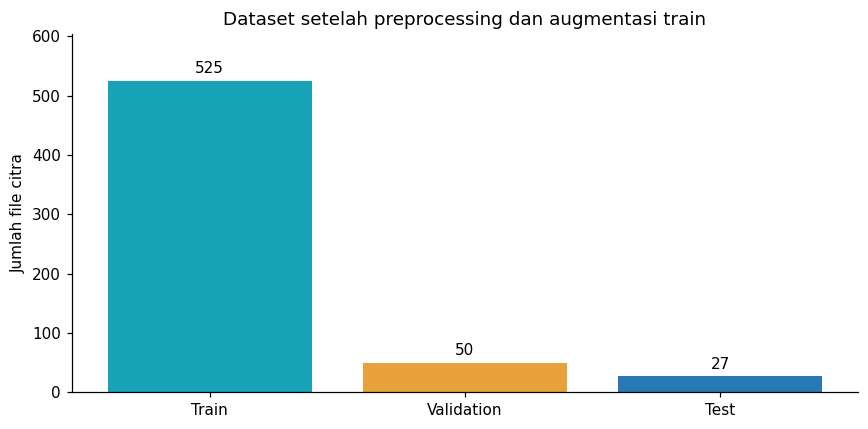

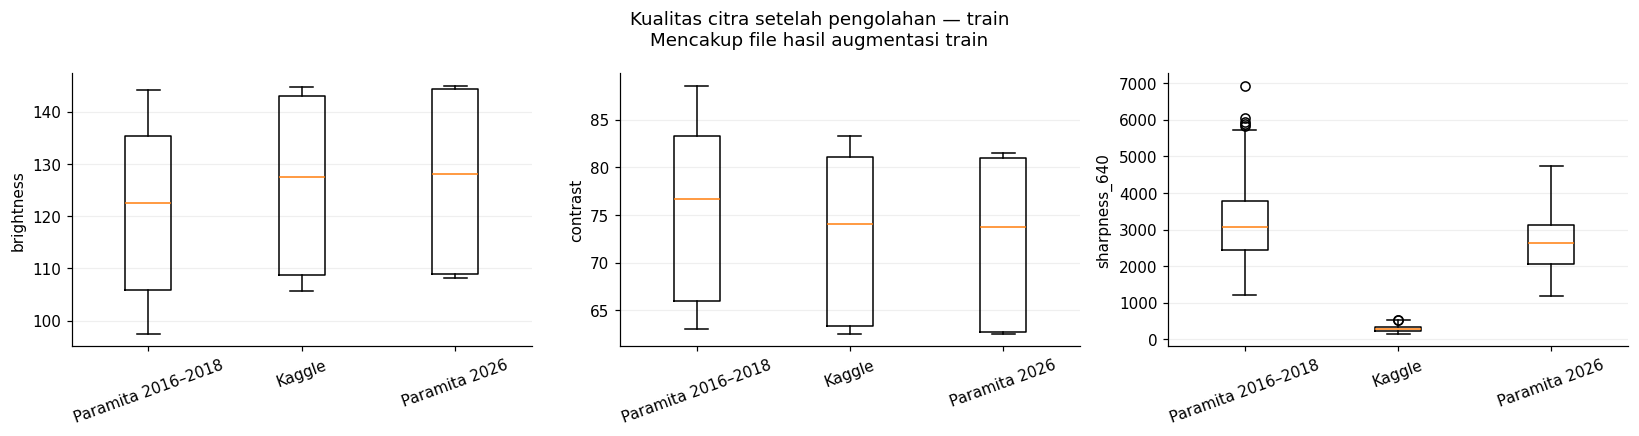

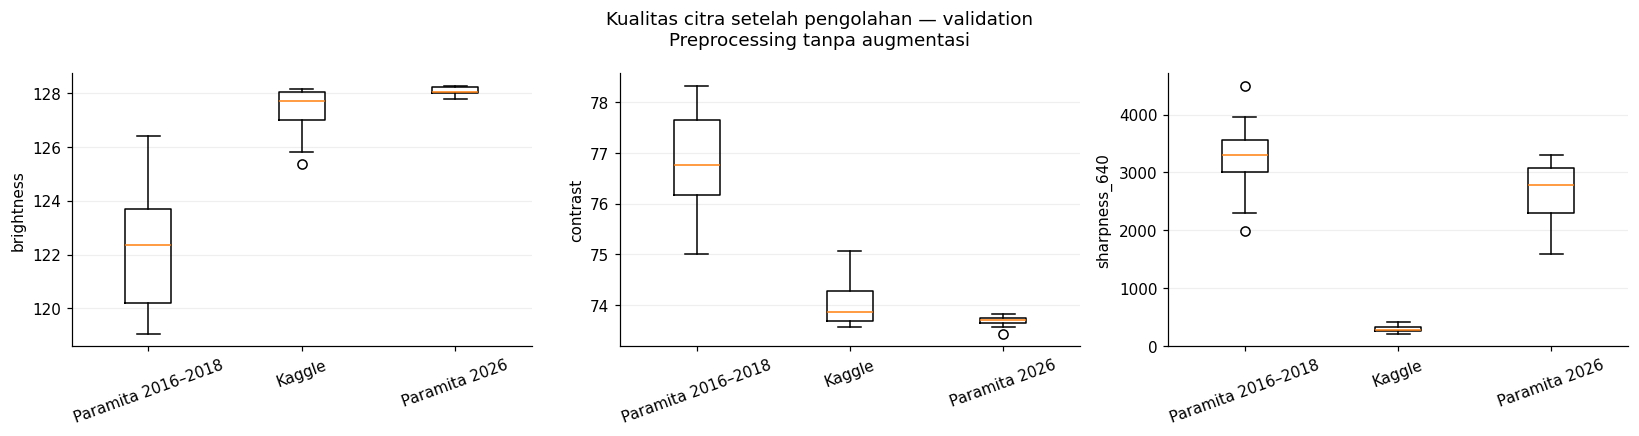

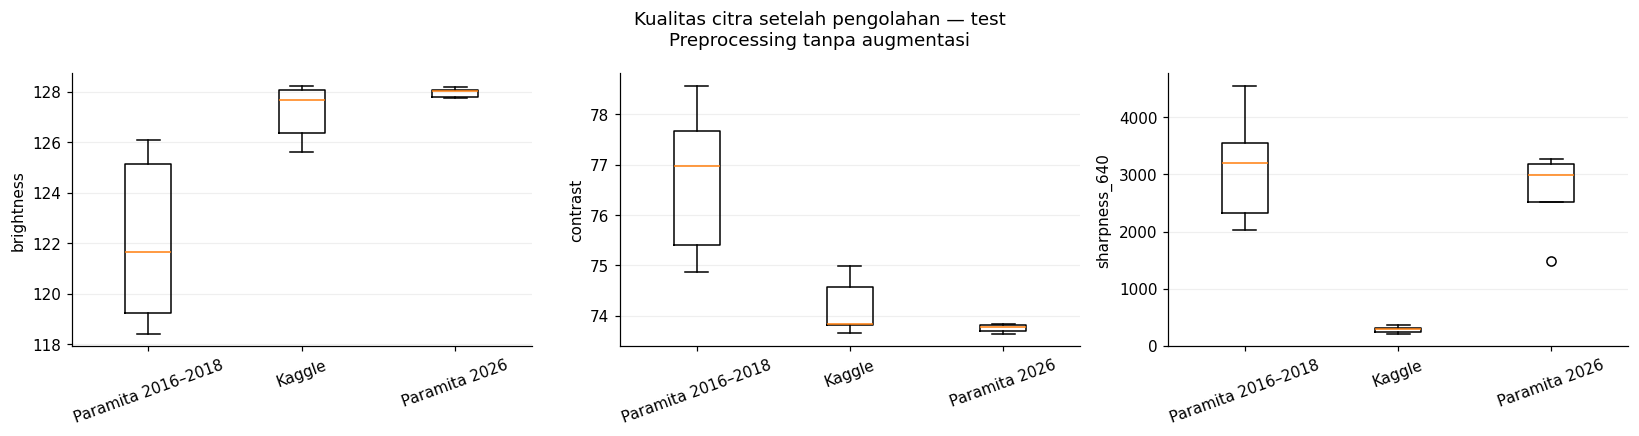


CATATAN INTERPRETASI
• Statistik dihitung dari file hasil ekspor yang sebenarnya.
• Statistik train mencakup versi augmentasi yang saling berkaitan.
• Validation dan test dianalisis terpisah tanpa augmentasi.
• Kenaikan sharpness_640 tidak otomatis membuktikan
  detail anatomis atau performa deteksi membaik.
• Persentase piksel hitam/putih membantu memeriksa clipping,
  tetapi juga dipengaruhi latar dan tulisan pada radiograf.
• Jumlah anotasi hasil augmentasi bukan objek independen baru.
• Sumber dan identitas citra dibaca dari manifest ekspor.
• Preprocessing memakai fungsi notebook sebelumnya, termasuk
  transformasi koordinat box saat EXIF orientation berubah.

Laporan tersimpan di: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_EDA_awal_sebelum_UTS/EDA_FDI_lengkap_20261031_140236/dataset_processed_statistik_20261031_140543_959751/laporan_EDA_setelah

STATISTIK DESKRIPTIF DATASET AKHIR GABUNGAN


,count,mean,std,min,25%,50%,75%,max,IQR
width,602.0,1983.854,11.270,1976.000,1976.000,1976.000,2000.000,2000.000,24.000
height,602.0,963.513,15.244,942.000,942.000,969.000,976.000,976.000,34.000
aspect_ratio,602.0,2.060,0.045,2.025,2.025,2.039,2.123,2.123,0.099
brightness,602.0,124.213,13.769,97.498,108.823,126.198,136.221,144.969,27.398
contrast,602.0,74.226,7.460,62.519,65.868,74.816,80.992,88.566,15.124
sharpness_640,602.0,2137.182,1502.358,148.870,345.859,2366.965,3266.262,6931.010,2920.403
black_pixels_pct,602.0,2.670,2.705,0.048,0.344,1.494,4.586,10.547,4.241
white_pixels_pct,602.0,4.056,5.790,0.000,0.000,0.353,12.656,13.814,12.656
n_annotations,602.0,13.218,5.447,1.000,10.000,13.000,19.000,20.000,9.000


Statistik gabungan memberi bobot lebih besar pada train karena augmentasi.


In [25]:
# ============================================================
# DESKRIPSI DAN STATISTIK DATASET SETELAH
# PREPROCESSING + AUGMENTASI TRAIN
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from IPython.display import display

# ============================================================
# 1. PATH DATASET HASIL — SUDAH DIPERBAIKI
# ============================================================

if "DATASET_AFTER" not in globals():
    raise RuntimeError("Jalankan cell ekspor tepat di atas terlebih dahulu.")
DATASET_AFTER = Path(DATASET_AFTER)
if not DATASET_AFTER.is_dir():
    raise FileNotFoundError(f"Folder ekspor tidak tersedia: {DATASET_AFTER}")
export_manifest = pd.read_csv(DATASET_AFTER / "manifest.csv")
if export_manifest["output"].duplicated().any():
    raise ValueError("Nama output berulang pada manifest.")
manifest_lookup = export_manifest.set_index("output")

REPORT_AFTER = DATASET_AFTER / "laporan_EDA_setelah"
REPORT_AFTER.mkdir(exist_ok=True)

print("Dataset hasil yang digunakan:", DATASET_AFTER)

EXT_AFTER = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def sumber_after(nama):
    stem = Path(nama).stem
    if stem not in manifest_lookup.index:
        raise ValueError(f"Citra tidak terdaftar pada manifest: {nama}")
    return str(manifest_lookup.loc[stem, "source"])

# ============================================================
# 2. TEMUKAN FOLDER SPLIT
# ============================================================

split_dirs = {}

for split, aliases in {
    "train": ["train"],
    "validation": ["valid", "val", "validation"],
    "test": ["test"]
}.items():
    matches = [
        DATASET_AFTER / alias
        for alias in aliases
        if (DATASET_AFTER / alias / "images").is_dir()
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Folder images untuk {split} tidak ditemukan "
            f"atau ambigu: {matches}"
        )

    split_dirs[split] = matches[0]

# ============================================================
# 3. BACA METADATA CITRA DAN LABEL HASIL
# ============================================================

rows_after = []

for split, folder in split_dirs.items():
    image_dir = folder / "images"
    label_dir = folder / "labels"

    image_paths = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in EXT_AFTER
    )

    print(f"Membaca {split}: {len(image_paths)} file citra")

    for p in image_paths:
        row = {
            "split": split,
            "source": sumber_after(p.name),
            "filename": p.name,
            "image_id": manifest_lookup.loc[p.stem, "image_id"],
            "original_filename": manifest_lookup.loc[p.stem, "original_filename"],
            "path": str(p),
            "readable": False,
            "n_annotations": np.nan,
            "label_status": "Tidak ditemukan",
            "width": np.nan,
            "height": np.nan,
            "aspect_ratio": np.nan,
            "brightness": np.nan,
            "contrast": np.nan,
            "sharpness_640": np.nan,
            "black_pixels_pct": np.nan,
            "white_pixels_pct": np.nan
        }

        label_path = (
            label_dir / p.relative_to(image_dir)
        ).with_suffix(".txt")

        if label_path.is_file():
            try:
                lines = [
                    line.strip()
                    for line in label_path.read_text(
                        encoding="utf-8"
                    ).splitlines()
                    if line.strip()
                ]

                # Format deteksi YOLO:
                # class_id x_center y_center width height
                for line in lines:
                    values = list(map(float, line.split()))

                    if len(values) != 5:
                        raise ValueError(
                            "Baris label bukan format deteksi YOLO."
                        )

                    if not np.isfinite(values).all():
                        raise ValueError("Label mengandung nilai nonfinite.")

                    if (
                        not values[0].is_integer()
                        or not 0 <= values[0] < 20
                    ):
                        raise ValueError(
                            "class_id harus bilangan bulat 0–19."
                        )

                    x, y, w, h = values[1:]

                    if not (
                        0 <= x <= 1 and 0 <= y <= 1
                        and 0 < w <= 1 and 0 < h <= 1
                    ):
                        raise ValueError("Koordinat box tidak valid.")

                row["n_annotations"] = len(lines)
                row["label_status"] = (
                    "Terbaca" if lines else "Label kosong"
                )

            except Exception as e:
                row["label_status"] = f"Perlu pemeriksaan: {e}"

        try:
            with Image.open(p) as im:
                im.load()
                gray = np.asarray(im.convert("L")).copy()

            # Tidak mengulang preprocessing.
            # Membaca piksel file hasil yang sudah tersimpan.
            h, w = gray.shape

            thumbnail = cv2.resize(
                gray,
                (640, max(3, round(h * 640 / w)))
            )

            row.update({
                "readable": True,
                "width": w,
                "height": h,
                "aspect_ratio": w / h,
                "brightness": float(gray.mean()),
                "contrast": float(gray.std()),
                "sharpness_640": float(
                    cv2.Laplacian(
                        thumbnail, cv2.CV_64F
                    ).var()
                ),
                "black_pixels_pct": float(
                    (gray == 0).mean() * 100
                ),
                "white_pixels_pct": float(
                    (gray == 255).mean() * 100
                )
            })

        except Exception as e:
            row["image_error"] = str(e)

        rows_after.append(row)

if not rows_after:
    raise RuntimeError("Tidak ada file citra pada dataset hasil.")

meta_after = pd.DataFrame(rows_after)

meta_after.to_csv(
    REPORT_AFTER / "metadata_setelah.csv",
    index=False
)

# ============================================================
# 4. DESKRIPSI DATASET PER SPLIT
# ============================================================

ringkasan_after = (
    meta_after.groupby("split")
    .agg(
        citra_sumber=("image_id", "nunique"),
        jumlah_file_citra=("filename", "size"),
        citra_dapat_dibaca=("readable", "sum"),
        file_label_terbaca=("n_annotations", "count"),
        jumlah_anotasi_terbaca=(
            "n_annotations",
            lambda x: x.sum(min_count=1)
        )
    )
    .reindex(["train", "validation", "test"])
)

print("\nDESKRIPSI DATASET SETELAH PREPROCESSING DAN AUGMENTASI")
display(ringkasan_after)

ringkasan_after.to_csv(
    REPORT_AFTER / "deskripsi_dataset_per_split.csv"
)

print(f"Total file citra: {len(meta_after):,}")

total_annotations = meta_after["n_annotations"].sum(min_count=1)

if pd.notna(total_annotations):
    print(
        "Total anotasi yang berhasil dibaca:",
        f"{total_annotations:,.0f}"
    )
else:
    print("Total anotasi belum dapat dihitung.")

print(
    "Jumlah file mencakup versi augmentasi, "
    "bukan jumlah pasien atau radiograf independen."
)

# ============================================================
# 5. KOMPOSISI SUMBER PER SPLIT
# ============================================================

komposisi_after = pd.crosstab(
    meta_after["source"],
    meta_after["split"]
).reindex(
    columns=["train", "validation", "test"],
    fill_value=0
)

print("\nKOMPOSISI FILE MENURUT SUMBER DAN SPLIT")
display(komposisi_after)

komposisi_after.to_csv(
    REPORT_AFTER / "komposisi_sumber_per_split.csv"
)

# ============================================================
# 6. FILE YANG PERLU DIPERIKSA
# ============================================================

masalah_after = meta_after.loc[
    (~meta_after["readable"])
    | (meta_after["n_annotations"].isna()),
    ["split", "filename", "readable", "label_status"]
]

print("\nFILE YANG PERLU DIPERIKSA")
display(masalah_after)

masalah_after.to_csv(
    REPORT_AFTER / "file_perlu_pemeriksaan.csv",
    index=False
)

# ============================================================
# 7. STATISTIK DESKRIPTIF PER SPLIT
# ============================================================

metrics_after = [
    "width", "height", "aspect_ratio",
    "brightness", "contrast", "sharpness_640",
    "black_pixels_pct", "white_pixels_pct",
    "n_annotations"
]

valid_after = meta_after.loc[
    meta_after["readable"]
].copy()

if valid_after.empty:
    raise RuntimeError("Seluruh citra hasil gagal dibaca.")

# Disusun per split agar tabel mudah dibaca.
statistik_list = []

for split in ["train", "validation", "test"]:
    subset = valid_after.loc[
        valid_after["split"] == split
    ]

    if subset.empty:
        continue

    table = subset[metrics_after].describe().T
    table["IQR"] = table["75%"] - table["25%"]
    table.index.name = "variabel"
    table = table.reset_index()
    table.insert(0, "split", split)
    statistik_list.append(table)

statistik_after = pd.concat(
    statistik_list, ignore_index=True
).set_index(["split", "variabel"])

print("\nSTATISTIK DESKRIPTIF PER SPLIT")
display(statistik_after.round(3))

statistik_after.to_csv(
    REPORT_AFTER / "statistik_deskriptif_per_split.csv"
)

# ============================================================
# 8. GRAFIK JUMLAH CITRA PER SPLIT
# ============================================================

counts = ringkasan_after["jumlah_file_citra"].fillna(0)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    ["Train", "Validation", "Test"],
    counts.to_numpy(),
    color=["#17A2B8", "#E9A23B", "#2878B5"]
)

ax.bar_label(bars, padding=3)
ax.set_ylabel("Jumlah file citra")
ax.set_title("Dataset setelah preprocessing dan augmentasi train")
ax.margins(y=.15)

fig.tight_layout()
fig.savefig(
    REPORT_AFTER / "jumlah_citra_per_split.png",
    dpi=160, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================
# 9. GRAFIK KUALITAS ANTARSUMBER PER SPLIT
# ============================================================

source_order = [
    "Paramita 2016–2018",
    "Kaggle",
    "Paramita 2026"
]

for split in ["train", "validation", "test"]:
    subset = valid_after.loc[
        valid_after["split"] == split
    ]

    sources_present = [
        s for s in source_order
        if (subset["source"] == s).any()
    ]

    if not sources_present:
        continue

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 4)
    )

    for ax, metric in zip(
        axes,
        ["brightness", "contrast", "sharpness_640"]
    ):
        values = [
            subset.loc[
                subset["source"] == s, metric
            ].dropna().to_numpy()
            for s in sources_present
        ]

        ax.boxplot(values)
        ax.set_xticks(
            range(1, len(sources_present) + 1),
            sources_present,
            rotation=20
        )
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=.2)

    fig.suptitle(
        f"Kualitas citra setelah pengolahan — {split}\n"
        + (
            "Mencakup file hasil augmentasi train"
            if split == "train"
            else "Preprocessing tanpa augmentasi"
        ),
        fontsize=12
    )

    fig.tight_layout()
    fig.savefig(
        REPORT_AFTER / f"kualitas_setelah_{split}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ============================================================
# 10. CATATAN INTERPRETASI
# ============================================================

print("""
CATATAN INTERPRETASI
• Statistik dihitung dari file hasil ekspor yang sebenarnya.
• Statistik train mencakup versi augmentasi yang saling berkaitan.
• Validation dan test dianalisis terpisah tanpa augmentasi.
• Kenaikan sharpness_640 tidak otomatis membuktikan
  detail anatomis atau performa deteksi membaik.
• Persentase piksel hitam/putih membantu memeriksa clipping,
  tetapi juga dipengaruhi latar dan tulisan pada radiograf.
• Jumlah anotasi hasil augmentasi bukan objek independen baru.
• Sumber dan identitas citra dibaca dari manifest ekspor.
• Preprocessing memakai fungsi notebook sebelumnya, termasuk
  transformasi koordinat box saat EXIF orientation berubah.
""")

print("Laporan tersimpan di:", REPORT_AFTER)
print("\nSTATISTIK DESKRIPTIF DATASET AKHIR GABUNGAN")
statistik_gabungan = valid_after[metrics_after].describe().T
statistik_gabungan["IQR"] = statistik_gabungan["75%"] - statistik_gabungan["25%"]
display(statistik_gabungan.round(3))
statistik_gabungan.to_csv(REPORT_AFTER / "statistik_deskriptif_gabungan.csv")
print("Statistik gabungan memberi bobot lebih besar pada train karena augmentasi.")
